# Customer Insights — o que os relatos acrescentam aos números do catálogo

O desafio da FIAP pede que os comentários ajudem a identificar atributos valorizados, problemas, padrões favoráveis e desfavoráveis e prioridades comerciais. O Notebook 03 selecionou comparações por função, perfis relativos e casos sensíveis ao comparador. Aqui investigamos em que medida os textos ajudam a explicar ou questionar essas prioridades.

O bloco é uma unidade de origem e pode reunir vários relatos. Frequências lexicais medem presença de expressões. As interpretações de polaridade são locais, apoiadas em leitura assistida de trechos, com validação humana independente pendente. A nota e a contagem são atributos do produto.

## 1 — Do diagnóstico comercial às perguntas sobre os relatos

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Permitir início pela raiz ou pela pasta do notebook, mantendo o módulo local.
pasta_metodos = next((c for p in [Path.cwd(), *Path.cwd().parents]
                      for c in [p, p/'amazon_sales_analise/customer_insights', p/'customer_insights']
                      if (c/'metodos_customer_insights_ml.py').is_file()), None)
if pasta_metodos is not None: sys.path.insert(0, str(pasta_metodos))
from metodos_customer_insights_ml import *
raiz = localizar_raiz()
tabelas = ler_tabelas(raiz)
validacoes, contexto_reviews, textos = validar_fontes(tabelas, raiz)
produtos = tabelas['produtos'][['product_id','categoria_nivel_1','categoria_nivel_2']].copy()
corpus, vinculos_textuais, pares_pg, perfis_completos, cobertura_perfis = preparar_corpus(tabelas)
visao_textual = agregar_produtos(perfis_completos, pares_pg, corpus)
print('Fontes validadas:',len(validacoes),'| produtos:',len(produtos),'| ocorrências:',len(textos))
display(textos[['ocorrencia_id','product_id','grupo_textual_id','review_content_original']].head(3)
    .assign(review_content_original=lambda d:d.review_content_original.str.slice(0,150)+' […]')
    .style.hide(axis='index').set_properties(**{'max-width':'420px','white-space':'normal'}))

Fontes validadas: 34 | produtos: 1351 | ocorrências: 1465


ocorrencia_id,product_id,grupo_textual_id,review_content_original
OC-000001,B07JW9H4J1,TXT-000001,"Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the quality.,This is a good product . Th […]"
OC-000002,B098NS6PVG,TXT-000002,I ordered this cable to connect my phone to Android Auto of car. The cable is really strong and the connection ports are really well made. I already h […]
OC-000003,B096MSW6CT,TXT-000003,"Not quite durable and sturdy,https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/71rIggrbUCL._SY88.jpg,Working good,https://m.media-amazon.com […]"


In [2]:
# A camada canônica mantém seis entidades. O bruto é conferência de literalidade.
from leitura_dados import ler_canonicas
import json
canonicas = ler_canonicas(raiz)
esquema = json.loads((raiz/"documentacao/schema_dados.json").read_text(encoding="utf-8"))
for nome, d in canonicas.items():
    spec = esquema["entidades"][nome]
    assert len(d)==spec["linhas"] and d.dtypes.astype(str).to_dict()==spec["tipos"]
    assert d.isna().sum().to_dict()==spec["nulos"]
    assert d[spec["chave"]].notna().all().all() and not d.duplicated(spec["chave"]).any()
p_canon = canonicas["produtos"]
o_canon = canonicas["ocorrencias_base"]
assert p_canon.categoria_id.isin(canonicas["categorias"].categoria_id).all()
origem_desc = p_canon.merge(o_canon[["ocorrencia_id","product_id","about_product"]],
    left_on=["ocorrencia_id_referencia","product_id"],right_on=["ocorrencia_id","product_id"],
    validate="one_to_one",suffixes=("_produto","_origem"),how="left")
assert origem_desc.about_product_produto.equals(origem_desc.about_product_origem)
r_canon = canonicas["reviews"]
aceito = r_canon[["review_title","review_content"]].fillna("").apply(lambda s:s.str.strip().ne("")).all(axis=1)
uso = r_canon.grupo_uso_textual
assert aceito.eq(uso.isin(["MAIOR_CONFIANCA","EXPLORATORIO"])).all()
universos = pd.Series({"Produtos":len(p_canon),"Ocorrências":len(o_canon),"Grupos exatos":len(corpus),
    "Pares produto–grupo":len(pares_pg),"IDs de review":len(r_canon),"Review completo aceito":aceito.sum(),
    "Maior confiança estrutural":uso.eq("MAIOR_CONFIANCA").sum(),"Exploratório":uso.eq("EXPLORATORIO").sum()})
assert universos.tolist()==[1351,1465,1212,1370,9269,171,70,101]
display(universos.to_frame("Registros"))

,Registros
Produtos,1351
Ocorrências,1465
Grupos exatos,1212
Pares produto–grupo,1370
IDs de review,9269
Review completo aceito,171
Maior confiança estrutural,70
Exploratório,101


| Evidência do Notebook 03 | Hipótese textual | Unidade e comparador | Método e destino |
|---|---|---|---|
| Cabos e fones A/B com preço igual em cada par | Compatibilidade, conforto e funcionamento podem diferir | Par no caminho, bloco e excerto | Ler atributo anunciado e o objeto do relato. Comparar presença no caminho (§5–6) |
| Ferros com desconto igual e preços distintos | Uso, peso e estado na entrega podem explicar percepções distintas | Ferros a seco, com apoio do caminho | Confrontar descrição e relato. Evidência de detalhe para BI (§5–6) |
| 45/63 fones mudam de classe no nível 2. Celular básico também é sensível | Comparar função e especificação muda a leitura de autonomia e áudio | A persistente/sensível, celulares básicos sem bloco em comum | Manter corte oficial e verificar sensibilidade em separado (§5–6) |
| A/B inverte contraste de desconto em Mobiles e Wearable | Referências a valor podem variar com composição e desconto local | Produto no ramo, quartis fixos de preço original | Contar expressões, revisar contraexemplos e explicitar denominador (§4–6) |
| Purificador A persistente e extremo de preço | Instalação, indicador e atendimento podem contextualizar o preço | Produto, descrição e trecho | Separar produto, água e serviço. Verificar hipótese com evidência operacional (§5) |

## 2 — Quais textos podem sustentar a comparação?

A leitura canônica conserva os textos integrais. As prévias servem à navegação e a conferência com o bruto verifica literalidade.

### Disponibilidade e características dos textos

**Pergunta:** quais campos estão disponíveis e quão heterogênea é sua extensão?

Ausências, strings vazias e campos apenas com espaços são contados separadamente. O teste com strip não modifica os originais.

In [3]:
campos = ["review_title_original", "review_content_original"]
disponibilidade = pd.DataFrame({
    "Ocorrências":len(textos), "Ausentes":textos[campos].isna().sum(),
    "Vazios":textos[campos].eq("").sum(),
    "Somente espaços":pd.Series({c:(textos[c].str.strip().eq("") & textos[c].ne("")).sum() for c in campos}),
})
display(disponibilidade)
comprimentos = pd.DataFrame({c:textos[c].str.len() for c in campos})
display(comprimentos.describe().rename(columns={"review_title_original":"Caracteres do título", "review_content_original":"Caracteres do comentário"}).style.format(precision=2, decimal=",", thousands="."))

,Ocorrências,Ausentes,Vazios,Somente espaços
review_title_original,1465,0,0,0
review_content_original,1465,0,0,0


,Caracteres do título,Caracteres do comentário
count,"1.465,00","1.465,00"
mean,"181,91","1.394,14"
std,"55,57","1.823,49"
min,"7,00","67,00"
25%,"140,00","505,00"
50%,"176,00","823,00"
75%,"217,00","1.388,00"
max,"407,00","18.547,00"


Todos os 1.465 blocos têm título e comentário, sem ausências, vazios ou campos apenas com espaços. Os títulos têm mediana de **176 caracteres**, quartis de **140 e 217** e extremos de **7 e 407**.

Os comentários têm mediana de **823**, quartis de **505 e 1.388**, média de **1.394,14** e desvio-padrão de **1.823,49 caracteres**. Variam de **67 a 18.547**. A cauda de blocos longos torna inadequado tratar cada linha como um depoimento curto de extensão semelhante. Comprimento não informa quantidade de autores ou reviews.

In [4]:
amostras = textos[["ocorrencia_id", "product_id", "review_content_original"]].copy()
amostras["Caracteres"] = amostras["review_content_original"].str.len()
amostras["Distância"] = (amostras["Caracteres"] - amostras["Caracteres"].median()).abs()
central = amostras.sort_values(["Distância", "ocorrencia_id"]).head(1).assign(Critério="Próximo à mediana")
extenso = amostras.sort_values(["Caracteres", "ocorrencia_id"], ascending=[False, True]).head(1).assign(Critério="Maior extensão")
exemplos = pd.concat([central, extenso])
exemplos["Excerto inicial"] = exemplos["review_content_original"].str.slice(0, 220)
display(exemplos[["Critério", "ocorrencia_id", "product_id", "Caracteres", "Excerto inicial"]].style.hide(axis="index").set_properties(**{"max-width":"420px", "white-space":"normal"}))

Critério,ocorrencia_id,product_id,Caracteres,Excerto inicial
Próximo à mediana,OC-000492,B09PLFJ7ZW,823,"The watch is good, the app is very bad, no Google fit integration or anything, watch face is barely customisable, I don't know why they used the new noise fit prime app with it, the app is very glitchy.If you want this w"
Maior extensão,OC-001057,B008QTK47Q,18547,"Update as on 28.10.2018:*********************************The power cord has developed twists beyond repair and the seperate cores are now visible,the insulation pvc of the cores doesn't look very durable.I don't know why"


A seleção usa distância ao comprimento mediano e maior extensão, com desempate pela chave de ocorrência. O primeiro trecho discute um relógio e seu aplicativo; o segundo começa com uma atualização datada sobre um cabo de ferro. Uma referência temporal dentro do texto não constitui histórico estruturado de preços ou avaliações. Nenhum conteúdo foi truncado na base.

In [5]:
padroes = {"Vírgulas":",", "Aspas":'"', "URL http(s)":r"https?://",
    "Fora de ASCII":r"[^\x00-\x7F]", "Devanágari":r"[\u0900-\u097F]",
    "Tâmil":r"[\u0B80-\u0BFF]", "Quebra de linha":r"[\r\n]"}
sinais = pd.DataFrame({nome:textos["review_content_original"].str.contains(padrao, regex=True) for nome,padrao in padroes.items()})
display(sinais.sum().to_frame("Ocorrências com o sinal (base: 1.465)"))
for escrita in ["Devanágari", "Tâmil"]:
    evidencia = textos.loc[sinais[escrita]].sort_values("ocorrencia_id").head(1).copy()
    evidencia["Trecho"] = evidencia["review_content_original"].str.extract("(.{0,30}" + padroes[escrita] + ".{0,90})", expand=False)
    print(escrita)
    display(evidencia[["ocorrencia_id", "product_id", "Trecho"]].style.hide(axis="index"))

,Ocorrências com o sinal (base: 1.465)
Vírgulas,1463
Aspas,93
URL http(s),233
Fora de ASCII,717
Devanágari,48
Tâmil,4
Quebra de linha,0


Devanágari


ocorrencia_id,product_id,Trecho
OC-000007,B08WRWPM22,"uit,good,Nice,Good quality,1.5एम का डाटा केबल मेरे लिए बहुत ही लाभदायक है । मैं इस केबल को लाइन में चार्ज करते समय फोन ब"


Tâmil


ocorrencia_id,product_id,Trecho
OC-000011,B08CF3D7QR,"charging, and value for money,பொருள் உடைய கடினத்தன்மையின் நன்றாக உள்ளது சார்ஜ் ஏறும் வேகம் 15wat,Not a fast charger. Ver"


Há **1.463 comentários com vírgulas**, **93 com aspas**, **233 com URLs** e **717 com caracteres fora de ASCII**; não há quebras de linha. As prévias apresentam frases sucessivas e pontuação interna: vírgulas não delimitam autores ou depoimentos de forma confiável.

Há caracteres devanágari em **48 ocorrências** e tâmil em **quatro**. Junto dos trechos em inglês, as evidências impedem presumir uniformidade linguística. Sistema de escrita não é detecção conclusiva de idioma; caracteres não ASCII também incluem símbolos e emojis. As contagens se sobrepõem. Esses sinais orientam inspeção posterior, sem análise de temas ou sentimentos.

### Repetição exata e rastreabilidade

**Pergunta:** quanto do material se repete dentro e entre produtos?

A comparação considera o par integral título–conteúdo, sem normalização. Verifica-se a correspondência entre pares e grupos nos dois sentidos, além da concordância do indicador de reutilização com a frequência maior que um.

In [6]:
assert textos.groupby("grupo_textual_id")[campos].nunique(dropna=False).eq(1).all().all()
assert textos.groupby(campos, dropna=False)["grupo_textual_id"].nunique().eq(1).all()
grupos = textos.groupby("grupo_textual_id").agg(Ocorrências=("ocorrencia_id","size"), Produtos=("product_id","nunique"))
assert textos["conteudo_reutilizado"].eq(textos["grupo_textual_id"].map(grupos["Ocorrências"]).gt(1)).all()
repetidos = grupos.loc[grupos["Ocorrências"].gt(1)]
compartilhados = grupos.loc[grupos["Produtos"].gt(1)]
pares_produto = textos.groupby(["product_id", "grupo_textual_id"]).size()
display(pd.Series({
    "Ocorrências textuais":len(textos), "Pares exatos distintos":len(textos[campos].drop_duplicates()),
    "Grupos repetidos":len(repetidos), "Ocorrências em grupos repetidos":repetidos["Ocorrências"].sum(),
    "Produtos em grupos repetidos":textos.loc[textos["grupo_textual_id"].isin(repetidos.index),"product_id"].nunique(),
    "Grupos entre produtos":len(compartilhados), "Ocorrências nesses grupos":compartilhados["Ocorrências"].sum(),
    "Reaparições adicionais do mesmo par no mesmo produto":(pares_produto-1).sum(),
    "Associações distintas produto e par":len(pares_produto),
}).to_frame("Quantidade"))

,Quantidade
Ocorrências textuais,1465
Pares exatos distintos,1212
Grupos repetidos,141
Ocorrências em grupos repetidos,394
Produtos em grupos repetidos,295
Grupos entre produtos,96
Ocorrências nesses grupos,294
Reaparições adicionais do mesmo par no mesmo produto,95
Associações distintas produto e par,1370


As **1.465 ocorrências** correspondem a **1.212 pares exatos**. Os **141 grupos repetidos** abrangem **394 ocorrências e 295 produtos distintos**. Há **96 grupos compartilhados entre produtos**, cobrindo **294 ocorrências**, e **95 reaparições adicionais** do mesmo par dentro do mesmo produto.

Uma comparação metodológica conservaria **1.370 associações produto–par** ou **1.212 pares globais**, em vez das 1.465 ocorrências. Não houve remoção global: cada unidade responde a uma pergunta diferente, e deduplicar sem preservar os vínculos apagaria associações com produtos. Repetição interna e entre produtos pode coexistir no mesmo grupo.

In [7]:
grupo_exemplo = compartilhados.sort_values(["Produtos", "Ocorrências"], ascending=False, kind="stable").index[0]
par_exemplo = pares_produto.loc[pares_produto.gt(1)].sort_values(ascending=False, kind="stable").index[0]
entre = textos.loc[textos["grupo_textual_id"].eq(grupo_exemplo)]
dentro = textos.loc[textos["product_id"].eq(par_exemplo[0]) & textos["grupo_textual_id"].eq(par_exemplo[1])]
for criterio, evidencia in [("Maior número de produtos no grupo", entre), ("Maior reaparição do par no produto", dentro)]:
    print(criterio, "— ocorrências:", len(evidencia), "produtos:", evidencia["product_id"].nunique())
    amostra = evidencia.sort_values("ocorrencia_id").head(5).copy()
    amostra["Início do título"] = amostra["review_title_original"].str.slice(0, 90)
    display(amostra[["ocorrencia_id", "source_index", "product_id", "grupo_textual_id", "Início do título"]].style.hide(axis="index"))

Maior número de produtos no grupo — ocorrências: 8 produtos: 8


ocorrencia_id,source_index,product_id,grupo_textual_id,Início do título
OC-000364,363,B0B4F2XCK3,TXT-000364,"Phone, camera, heating - works for me, may not for all,Good Mobile,Good but not excellent"
OC-000400,399,B0B4F3QNDM,TXT-000364,"Phone, camera, heating - works for me, may not for all,Good Mobile,Good but not excellent"
OC-000410,409,B0B4F2TTTS,TXT-000364,"Phone, camera, heating - works for me, may not for all,Good Mobile,Good but not excellent"
OC-000420,419,B0B4F52B5X,TXT-000364,"Phone, camera, heating - works for me, may not for all,Good Mobile,Good but not excellent"
OC-000426,425,B0B4F5L738,TXT-000364,"Phone, camera, heating - works for me, may not for all,Good Mobile,Good but not excellent"


Maior reaparição do par no produto — ocorrências: 3 produtos: 1


ocorrencia_id,source_index,product_id,grupo_textual_id,Início do título
OC-000070,69,B01GGKYKQM,TXT-000070,"You can trust on this one,The best usb cable,Wel build just like original .,Nice!!,Working"
OC-000563,562,B01GGKYKQM,TXT-000070,"You can trust on this one,The best usb cable,Wel build just like original .,Nice!!,Working"
OC-000975,974,B01GGKYKQM,TXT-000070,"You can trust on this one,The best usb cable,Wel build just like original .,Nice!!,Working"


A primeira evidência seleciona o grupo com mais produtos, desempatando pelo número de ocorrências e pela ordem das chaves; a segunda seleciona a maior frequência do par produto–grupo, mantendo a ordem das chaves nos empates. Exibem-se até cinco ocorrências de cada caso, com o total explicitado.

Ocorrência e source_index localizam a origem; grupo_textual_id representa igualdade integral verificada, não apenas semelhança do excerto. Iguais não significam avaliações independentes, e diferentes não comprovam autores distintos.

### Cobertura textual dos produtos e categorias

**Pergunta:** quais produtos estão cobertos e quanto a unidade escolhida altera a representação?

O vínculo com produtos é muitos-para-um. Não se utilizam posições de review ou usuário para expandir os textos: isso multiplicaria blocos sem estabelecer autoria verificável.

In [8]:
textos_produtos = textos.merge(produtos, on="product_id", how="left", validate="many_to_one", indicator=True)
assert len(textos_produtos)==len(textos) and textos_produtos["_merge"].eq("both").all()
print("Produtos com bloco:",textos_produtos["product_id"].nunique(),"de",len(produtos))
print("Produtos sem bloco:",(~produtos["product_id"].isin(textos["product_id"])).sum())
blocos_por_produto = textos.groupby("product_id").size()
display(blocos_por_produto.value_counts().sort_index().rename_axis("Ocorrências textuais por produto").to_frame("Produtos distintos"))
display(textos_produtos.groupby("categoria_nivel_1").agg(
    Produtos_com_bloco=("product_id","nunique"), Ocorrências_textuais=("ocorrencia_id","size"),
    Pares_exatos_distintos=("grupo_textual_id","nunique"),
).sort_values("Produtos_com_bloco",ascending=False))

Produtos com bloco: 1351 de 1351
Produtos sem bloco: 0


,Produtos distintos
Ocorrências textuais por produto,
1,1259
2,70
3,22


,Produtos_com_bloco,Ocorrências_textuais,Pares_exatos_distintos
categoria_nivel_1,,,
Electronics,490,526,392
Home&Kitchen,448,448,448
Computers&Accessories,375,453,334
OfficeProducts,31,31,31
MusicalInstruments,2,2,2
HomeImprovement,2,2,2
Car&Motorbike,1,1,1
Health&PersonalCare,1,1,1
Toys&Games,1,1,1


Todos os **1.351 produtos** têm bloco associado: **1.259 com uma ocorrência, 70 com duas e 22 com três**. Cobertura de IDs não significa cobertura completa das avaliações nas páginas.

Electronics reúne **490 produtos, 526 ocorrências e 392 pares distintos**; Computers&Accessories, **375, 453 e 334**; Home&Kitchen, **448 nas três unidades**. Contar ocorrências atribui peso adicional a reaparições, principalmente nas duas primeiras categorias. Contar pares globais pode esconder quantos produtos compartilham conteúdo. Contagens distintas por categoria também não devem ser presumidas aditivas sem verificar compartilhamentos.

### Reutilização entre produtos por categoria

**Pergunta:** que proporção das ocorrências de cada categoria contém um par também associado a outro produto?

O critério é mais de um product_id por grupo textual, não apenas o indicador de repetição. A junção já validada é reutilizada; o denominador é o número de ocorrências da categoria.

In [9]:
cobertura_reuso = textos_produtos.copy()
produtos_por_grupo = textos.groupby("grupo_textual_id")["product_id"].nunique()
cobertura_reuso["compartilhado_entre_produtos"] = cobertura_reuso["grupo_textual_id"].map(produtos_por_grupo).gt(1)
reuso_categoria = cobertura_reuso.groupby("categoria_nivel_1").agg(
    Ocorrências=("ocorrencia_id", "size"),
    Ocorrências_compartilhadas=("compartilhado_entre_produtos", "sum"),
)
reuso_categoria["Percentual das ocorrências"] = reuso_categoria["Ocorrências_compartilhadas"] / reuso_categoria["Ocorrências"] * 100
display(reuso_categoria.sort_values("Ocorrências", ascending=False).style.format(precision=2, decimal=",", thousands="."))
print("Total de ocorrências compartilhadas:", cobertura_reuso["compartilhado_entre_produtos"].sum())
print("Grupos que atravessam categorias principais:", textos_produtos.groupby("grupo_textual_id")["categoria_nivel_1"].nunique().gt(1).sum())

,Ocorrências,Ocorrências_compartilhadas,Percentual das ocorrências
categoria_nivel_1,,,
Electronics,526,180,"34,22"
Computers&Accessories,453,114,"25,17"
Home&Kitchen,448,0,"0,00"
OfficeProducts,31,0,"0,00"
MusicalInstruments,2,0,"0,00"
HomeImprovement,2,0,"0,00"
Car&Motorbike,1,0,"0,00"
Health&PersonalCare,1,0,"0,00"
Toys&Games,1,0,"0,00"


Total de ocorrências compartilhadas: 294
Grupos que atravessam categorias principais: 0


Electronics tem **180 de 526 ocorrências compartilhadas entre produtos (34,22%)**; Computers&Accessories, **114 de 453 (25,17%)**; Home&Kitchen, **zero de 448**. As demais categorias também não apresentam esse compartilhamento. O total é **294**, sem grupos atravessando categorias principais.

A reutilização desigual pode aumentar artificialmente frequências de menções quando se contam ocorrências. Não é medida de satisfação, qualidade ou vendas. Ausência de compartilhamento não comprova independência de opiniões.

### A.2 — Cobertura das perguntas herdadas do N03
Disponibilidade significa conteúdo não vazio; não confirma idioma, relevância ou rótulos. Os perfis usam cortes fixos por categoria principal, nunca recalculados após seleção. A e B são comparadores relativos, não classes de sentimento.

In [10]:
display(cobertura_perfis)
display(perfis_completos.groupby('categoria_nivel_1')[['limite_nota','limite_contagem']].first().round(2))
display(corpus.triagem_escrita.value_counts().rename_axis('Triagem, não idioma confirmado').to_frame('Grupos'))
display(corpus.caracteres.describe().round(1).to_frame('Caracteres por conteúdo, grupo exato'))
display(corpus[['tem_url','sinal_devanagari','sinal_tamil','sinal_outros_sistemas_indicos']].sum().to_frame('Grupos com sinal; contagens sobrepostas'))

,Produtos,Grupos,Ocorrências
perfil_completo,,,
A,212,190,241
Alta/baixa,241,218,253
Ausência,3,3,3
B,299,258,332
Baixa/baixa,330,315,349
Empate,228,190,249
Fora do recorte,38,38,38


,limite_nota,limite_contagem
categoria_nivel_1,,
Car&Motorbike,3.8,1118.0
Computers&Accessories,4.2,7317.0
Electronics,4.1,9129.5
Health&PersonalCare,4.0,3663.0
Home&Kitchen,4.1,2305.5
HomeImprovement,4.25,4283.0
MusicalInstruments,3.9,44441.0
OfficeProducts,4.3,4426.0
Toys&Games,4.3,15867.0


,Grupos
"Triagem, não idioma confirmado",
Sem escrita índica detectada; idioma não confirmado,1155
Escrita índica presente; idioma não confirmado,57


,"Caracteres por conteúdo, grupo exato"
count,1212.0
mean,1326.6
std,1765.9
min,67.0
25%,492.0
50%,783.0
75%,1340.0
max,18547.0


,Grupos com sinal; contagens sobrepostas
tem_url,205
sinal_devanagari,48
sinal_tamil,2
sinal_outros_sistemas_indicos,9


A detecção disponível aqui é **triagem de sistemas de escrita**, não identificação automática confiável de idioma. Escrita latina pode conter inglês ou idiomas romanizados; devanágari não identifica sozinho hindi. Textos mistos permanecem no corpus. Os métodos lexicais ingleses e o vocabulário estatístico não garantem cobertura de todas as línguas. A anotação entregue ao final deixa o idioma por confirmar, sem inventar confiança.

In [11]:
contexto_corpus = pares_pg.merge(corpus[["grupo_textual_id","elegivel_busca","caracteres","tem_url",
    "triagem_escrita"]],on="grupo_textual_id",validate="many_to_one").merge(
    visao_textual[["product_id","categoria_nivel_1","perfil_completo"]],on="product_id",validate="many_to_one")
contexto_corpus["Compartilhado"] = contexto_corpus.grupo_textual_id.map(
    pares_pg.groupby("grupo_textual_id").product_id.nunique()).gt(1)
contexto_corpus["Escrita índica"] = contexto_corpus.triagem_escrita.str.startswith("Escrita índica")
contexto_corpus["Trecho legível candidato"] = contexto_corpus.grupo_textual_id.map(
    corpus.set_index("grupo_textual_id").texto_busca.str.contains(r"[^\W\d_]",regex=True))
def quadro_qualidade(eixo):
    return contexto_corpus.groupby(eixo).agg(Produtos=("product_id","nunique"),Grupos=("grupo_textual_id","nunique"),
        Pares=("grupo_textual_id","size"),Mediana_caracteres=("caracteres","median"),
        Pares_com_URL=("tem_url","sum"),Pares_com_escrita_índica=("Escrita índica","sum"),
        Pares_compartilhados=("Compartilhado","sum"),Pares_com_letras=("Trecho legível candidato","sum"))
qualidade_perfil = quadro_qualidade("perfil_completo")
qualidade_categoria = quadro_qualidade("categoria_nivel_1")
display(qualidade_perfil,qualidade_categoria)

,Produtos,Grupos,Pares,Mediana_caracteres,Pares_com_URL,Pares_com_escrita_índica,Pares_compartilhados,Pares_com_letras
perfil_completo,,,,,,,,
A,212,190,220,719.0,41,21,48,220
Alta/baixa,241,218,243,845.0,42,5,42,243
Ausência,3,3,3,446.0,0,0,0,3
B,299,258,303,954.0,43,13,74,303
Baixa/baixa,330,315,331,681.0,55,22,28,331
Empate,228,190,232,971.5,40,4,62,232
Fora do recorte,38,38,38,598.5,5,1,0,38


,Produtos,Grupos,Pares,Mediana_caracteres,Pares_com_URL,Pares_com_escrita_índica,Pares_compartilhados,Pares_com_letras
categoria_nivel_1,,,,,,,,
Car&Motorbike,1,1,1,1069.0,0,0,0,1
Computers&Accessories,375,334,385,783.0,71,13,87,385
Electronics,490,392,499,1007.0,67,25,167,499
Health&PersonalCare,1,1,1,1843.0,0,0,0,1
Home&Kitchen,448,448,448,709.5,83,27,0,448
HomeImprovement,2,2,2,1048.5,0,0,0,2
MusicalInstruments,2,2,2,5118.5,0,0,0,2
OfficeProducts,31,31,31,544.0,5,1,0,31
Toys&Games,1,1,1,1001.0,0,0,0,1


Os sinais de escrita, presença de letras e URLs são triagens. A legibilidade de um trecho e o idioma de um relato ainda exigem leitura. Cobertura por perfil pode incluir o mesmo grupo em mais de um produto.

## B — Preparação moderada e dependências
### B.1 — Diagnóstico antes de normalizar

**Pergunta:** quais diferenças de representação e espaçamento exigem padronização?

Títulos e comentários são verificados separadamente. NFC compara representações Unicode canonicamente equivalentes, sem tradução, transliteração ou remoção de acentos. Espaços repetidos, espaços não separáveis e margens são examinados antes de aplicar qualquer regra. URLs são diagnosticadas, mas não presumidas erros.

In [12]:
diagnostico_preparacao = pd.DataFrame(index=campos)
for campo in campos:
    serie = textos[campo]
    diagnostico_preparacao.loc[campo, "Espaços comuns repetidos"] = serie.str.contains(r" {2,}").sum()
    diagnostico_preparacao.loc[campo, "Espaço não separável"] = serie.str.contains("\u00a0", regex=False).sum()
    diagnostico_preparacao.loc[campo, "Espaços nas margens"] = serie.ne(serie.str.strip()).sum()
    diagnostico_preparacao.loc[campo, "Representação diferente em NFC"] = serie.ne(serie.str.normalize("NFC")).sum()
    diagnostico_preparacao.loc[campo, "URL http(s)"] = serie.str.contains(r"https?://").sum()
display(diagnostico_preparacao.astype(int))

,Espaços comuns repetidos,Espaço não separável,Espaços nas margens,Representação diferente em NFC,URL http(s)
review_title_original,89,0,0,2,1
review_content_original,541,8,0,2,233


In [13]:
import re
excertos_diagnostico = []
for campo, padrao, motivo in [
    ("review_title_original", r" {2,}", "Espaços repetidos no título"),
    ("review_content_original", "\u00a0", "Espaço não separável no comentário"),
    ("review_title_original", r"https?://", "URL no título"),
]:
    caso = textos.loc[textos[campo].str.contains(padrao)].sort_values("ocorrencia_id").head(1)
    for _, linha in caso.iterrows():
        inicio = re.search(padrao, linha[campo]).start()
        excertos_diagnostico.append({"Ocorrência":linha["ocorrencia_id"], "Situação":motivo,
            "Excerto (representação literal)":repr(linha[campo][max(0,inicio-30):inicio+100])})
display(pd.DataFrame(excertos_diagnostico).style.hide(axis="index").set_properties(**{"max-width":"480px", "white-space":"pre-wrap"}))

Ocorrência,Situação,Excerto (representação literal)
OC-000016,Espaços repetidos no título,"'his product 8months It is done I have not faced any problem so far, its build quality best,I really liked this one.,Very strong a'"
OC-000362,Espaço não separável no comentário,'hone yet under 20K segmentPros\xa0Almost half the price of Galaxy A53Exynos 1280 is a solid performerExcellent 120Hz display with smo'
OC-001382,URL no título,"'ता है चाहे पत्थर भी दाल दो।😂। https://youtu.be/WBPca3j306k,Noice is high compared to others,Five star product,BEST MIXI,Best in th'"


Há **89 títulos e 541 comentários com espaços comuns repetidos**, além de **oito comentários com espaço não separável**. Nenhum campo tem espaços nas margens. NFC modifica a representação de **dois títulos e dois comentários**. As situações podem se sobrepor; suas quantidades não devem ser somadas.

Há **uma ocorrência com URL no título e 233 no comentário**. Os excertos são escolhidos pela primeira chave que satisfaz cada padrão, mostrando o entorno do sinal. A representação literal torna visível o espaço não separável. URLs serão mantidas: sem uma regra de fronteira validada, substituí-las pode retirar pontuação ou texto adjacente. Uma versão sem links não é necessária nesta preparação.

Justificam-se NFC e redução de sequências de espaços horizontais a um espaço comum. A regra mantém limites de palavras, maiúsculas, pontuação, negações, emojis e sistemas de escrita. Não será aplicada remoção nas margens, pois o diagnóstico não identificou essa necessidade.

### Versões normalizadas com originais preservados

**Pergunta:** como aplicar apenas as regras justificadas mantendo rastreabilidade?

textos_preparados conserva todas as colunas da fonte e acrescenta duas versões derivadas. NFC é aplicada antes dos espaços. A expressão de espaços exclui quebras de linha, preservando essa estrutura caso esteja presente. O grupo textual continua identificando igualdade literal anterior à normalização.

In [14]:
textos_preparados = textos.copy()
titulos_nfc = textos["review_title_original"].str.normalize("NFC")
comentarios_nfc = textos["review_content_original"].str.normalize("NFC")
textos_preparados["titulo_normalizado"] = titulos_nfc.str.replace(r"[^\S\r\n]+", " ", regex=True)
textos_preparados["comentario_normalizado"] = comentarios_nfc.str.replace(r"[^\S\r\n]+", " ", regex=True)
modificacoes = pd.DataFrame({
    "Alterados por NFC": [textos[campos[0]].ne(titulos_nfc).sum(), textos[campos[1]].ne(comentarios_nfc).sum()],
    "Alterados por espaços após NFC": [titulos_nfc.ne(textos_preparados["titulo_normalizado"]).sum(), comentarios_nfc.ne(textos_preparados["comentario_normalizado"]).sum()],
    "Alterados no resultado final": [textos[campos[0]].ne(textos_preparados["titulo_normalizado"]).sum(), textos[campos[1]].ne(textos_preparados["comentario_normalizado"]).sum()],
}, index=["Títulos", "Comentários"])
display(modificacoes)

,Alterados por NFC,Alterados por espaços após NFC,Alterados no resultado final
Títulos,2,89,91
Comentários,2,544,545


O resultado modifica **91 títulos e 545 comentários**. A etapa de espaços altera **89 títulos e 544 comentários**, após NFC. O número de comentários alterados por espaços é maior que os 541 com espaços comuns repetidos porque inclui espaços não separáveis. Algumas ocorrências acumulam NFC e espaço, por isso alterações por etapa não equivalem à soma de blocos distintos.

A maioria das representações já era utilizável. O tratamento é moderado, sem inferir palavras ausentes, separar depoimentos ou alterar a classificação comercial.

### Antes/depois e integridade

**Pergunta:** o que mudou nos exemplos e a normalização criou novas igualdades?

Os exemplos selecionam alterações efetivas: NFC no título, espaços no título e espaços no comentário. Dentro de cada regra, usa-se a primeira ocorrencia_id. O excerto é centralizado na primeira diferença, e a representação literal permite reconhecer espaços e caracteres combinantes.

In [15]:
exemplos_alteracoes = []
for antes, depois, regra in [
    (textos["review_title_original"], titulos_nfc, "NFC no título"),
    (titulos_nfc, textos_preparados["titulo_normalizado"], "Espaços no título"),
    (comentarios_nfc, textos_preparados["comentario_normalizado"], "Espaços no comentário"),
]:
    candidatos = textos.loc[antes.ne(depois)].sort_values("ocorrencia_id").head(1)
    for indice, linha in candidatos.iterrows():
        original, normal = antes.loc[indice], depois.loc[indice]
        posicao = next((i for i,(a,b) in enumerate(zip(original, normal)) if a != b), min(len(original),len(normal)))
        inicio = max(0, posicao-30)
        exemplos_alteracoes.append({"Ocorrência":linha["ocorrencia_id"], "Regra":regra,
            "Antes":repr(original[inicio:posicao+90]), "Depois":repr(normal[inicio:posicao+90])})
display(pd.DataFrame(exemplos_alteracoes).style.hide(axis="index").set_properties(**{"max-width":"350px", "white-space":"pre-wrap"}))

Ocorrência,Regra,Antes,Depois
OC-000103,NFC no título,"'ভালই কাজ করছে, পয়সা উসুল।,Just what I wanted.. works perfect,Great 👍,Good,Works fine with my Samsung smart'","'ভালই কাজ করছে, পয়সা উসুল।,Just what I wanted.. works perfect,Great 👍,Good,Works fine with my Samsung smar'"
OC-000016,Espaços no título,"'is product 8months It is done I have not faced any problem so far, its build quality best,I really liked this one.,Very'","'is product 8months It is done I have not faced any problem so far, its build quality best,I really liked this one.,Very '"
OC-000007,Espaços no comentário,'मेरे लिए बहुत ही लाभदायक है । मैं इस केबल को लाइन में चार्ज करते समय फोन बहुत आराम से उपयोग कर पा रहा हु । आप इस केबल ','मेरे लिए बहुत ही लाभदायक है । मैं इस केबल को लाइन में चार्ज करते समय फोन बहुत आराम से उपयोग कर पा रहा हु । आप इस केबल से'


In [16]:
pd.testing.assert_frame_equal(textos_preparados[textos.columns], textos, check_exact=True)
assert textos_preparados["ocorrencia_id"].is_unique
print("Dimensões antes:", textos.shape, "depois:", textos_preparados.shape)
print("Produtos antes/depois:", textos["product_id"].nunique(), textos_preparados["product_id"].nunique())
pares_normalizados = ["titulo_normalizado", "comentario_normalizado"]
quantidades_pares = pd.Series({
    "Pares originais distintos":len(textos[campos].drop_duplicates()),
    "Pares normalizados distintos":len(textos_preparados[pares_normalizados].drop_duplicates()),
    "Pares normalizados reunindo grupos originais diferentes":textos_preparados.groupby(pares_normalizados, dropna=False)["grupo_textual_id"].nunique().gt(1).sum(),
})
display(quantidades_pares.to_frame("Quantidade"))
print("Campos originais, chaves e vínculos preservados integralmente na comparação de valores.")

Dimensões antes: (1465, 7) depois: (1465, 9)
Produtos antes/depois: 1351 1351


,Quantidade
Pares originais distintos,1212
Pares normalizados distintos,1212
Pares normalizados reunindo grupos originais diferentes,0


Campos originais, chaves e vínculos preservados integralmente na comparação de valores.


As **1.465 ocorrências e os 1.351 produtos** foram preservados. A tabela passa de sete para nove colunas, sem multiplicação ou exclusão de linhas. A comparação integral inclui os dois campos originais, product_id, ocorrencia_id, source_index e grupo_textual_id.

Há **1.212 pares distintos antes e depois**, e **nenhum par normalizado reúne grupos originais diferentes**. Portanto, não surgiu nova igualdade entre grupos pela preparação aplicada. O identificador original permanece inalterado e não é redefinido como classificação semântica.

### B.2 — Quase repetição e componentes de dependência
Triagem por cosseno de TF-IDF de caracteres (3–5), limiar 0,90; 0,80 e 0,95 mostram sensibilidade. São similaridades lexicais, não equivalência semântica demonstrada. Texto bruto/grupo exato não é fundido. Produto–grupo e review contextual–grupo formam componentes; pares próximos acrescentam arestas apenas para planejar separação conservadora. Não se fragmenta por vírgulas.

In [17]:
pares_proximos = similaridade_proxima(corpus)
comp_exatos = componentes(corpus,vinculos_textuais,contexto_reviews)
comp_ampliados = componentes(corpus,vinculos_textuais,contexto_reviews,pares_proximos.loc[pares_proximos.cosseno.ge(.90)])
diagnostico_dependencias=[]
for limiar in [None,.80,.90,.95]:
    cp=comp_exatos if limiar is None else componentes(corpus,vinculos_textuais,contexto_reviews,pares_proximos.loc[pares_proximos.cosseno.ge(limiar)])
    diagnostico_dependencias.append({'Critério':'Exato' if limiar is None else f'Cosseno ≥ {limiar}', 'Pares próximos':0 if limiar is None else int(pares_proximos.cosseno.ge(limiar).sum()),'Componentes':cp.componente.nunique(),'Maior (grupos)':int(cp.componente.value_counts().max())})
display(pd.DataFrame(diagnostico_dependencias))
display(pares_proximos.head(6).round(4))
assert comp_exatos.componente.nunique()==1181
for gid in pares_proximos.head(1)[['grupo_a','grupo_b']].to_numpy().ravel():
    row=corpus.set_index('grupo_textual_id').loc[gid]
    print(gid, '— prévia:',row.review_content[:380]+' […]')

,Critério,Pares próximos,Componentes,Maior (grupos)
0,Exato,0,1181,4
1,Cosseno ≥ 0.8,36,1181,4
2,Cosseno ≥ 0.9,35,1181,4
3,Cosseno ≥ 0.95,30,1181,4


,grupo_a,grupo_b,cosseno
0,TXT-000496,TXT-000767,1.0
1,TXT-000071,TXT-000980,1.0
2,TXT-000427,TXT-000673,1.0
3,TXT-000001,TXT-000081,1.0
4,TXT-000001,TXT-000090,1.0
5,TXT-000081,TXT-000090,1.0


TXT-000496 — prévia: I got it for 1499 and I guess for this price it's good enough. Don't buy if you are buying it for than this price. If you just wanna try out a smart watch, this is really nice. But if you are expecting too many features in it , then go for a pricier one. At least for this watch, u don't have too many features, and you have to use your phone to set up most of the things ( like a […]
TXT-000767 — prévia: I got it for 1499 and I guess for this price it's good enough. Don't buy if you are buying it for than this price. If you just wanna try out a smart watch, this is really nice. But if you are expecting too many features in it , then go for a pricier one. At least for this watch, u don't have too many features, and you have to use your phone to set up most of the things ( like a […]


Mesmo um cosseno alto pode refletir termos comuns ou trechos copiados com opiniões adicionais. A triagem amplia a proteção contra sobreposição, mas não certifica independência semântica. O Notebook 05 usa os componentes ampliados em subamostras; a execução é exploratória sobre este snapshot, sem promessa de generalização.

## C — Menções, exemplos contrários e comparações locais
### C.1 — Baseline lexical preservado

**Pergunta:** quais características e experiências aparecem nos textos e qual é sua abrangência sem confundir menções com opiniões individuais?

A exploração começa pelos pares globais para não privilegiar conteúdos repetidos. As associações produto–grupo permanecem separadas para recuperar todos os produtos vinculados. Ocorrências continuam disponíveis para conferir o original. Diferentes grupos textuais não comprovam autores ou avaliações independentes.

In [18]:
grupos_lexicais = textos_preparados.sort_values("ocorrencia_id").drop_duplicates("grupo_textual_id").copy()
relacoes_textuais = textos_preparados[["product_id", "grupo_textual_id"]].drop_duplicates()
display(pd.Series({
    "Grupos textuais globais":len(grupos_lexicais),
    "Associações produto–grupo":len(relacoes_textuais),
    "Ocorrências para rastreabilidade":len(textos_preparados),
    "Produtos distintos":textos_preparados["product_id"].nunique(),
}).to_frame("Quantidade"))

,Quantidade
Grupos textuais globais,1212
Associações produto–grupo,1370
Ocorrências para rastreabilidade,1465
Produtos distintos,1351


São **1.212 grupos**, **1.370 associações**, **1.465 ocorrências** e **1.351 produtos**. A primeira ocorrência em ordem de chave representa cada grupo na exploração, mantendo títulos, comentários e IDs. A tabela de relações conserva todos os vínculos; a escolha de um representante global não elimina os demais produtos.

## 3 — O que os produtos anunciam?

O campo about_product vem da ocorrência comercial de referência. Usamos barras verticais como indício de estrutura do anúncio e contamos conflitos literais para identificar onde há versões. Atributos anunciados orientam a leitura, sem validar a especificação ou o desempenho.

In [19]:
desc = p_canon[["product_id","about_product","conflito_descricao"]].merge(
    visao_textual[["product_id","categoria_nivel_1","perfil_completo"]],on="product_id",validate="one_to_one")
desc["caracteres"] = desc.about_product.str.len()
desc["Disponível"] = desc.about_product.fillna("").str.strip().ne("")
desc["segmentos_barra"] = desc.about_product.str.count(r"\|").add(1).where(desc["Disponível"])
variantes = o_canon.groupby("product_id").about_product.nunique(dropna=False)
assert desc.product_id.map(variantes).gt(1).eq(desc.conflito_descricao).all()
resumo_desc = desc.groupby("categoria_nivel_1").agg(Produtos=("product_id","size"),Descrição=("Disponível","sum"),
    Mediana_caracteres=("caracteres","median"),Q1=("caracteres",lambda s:s.quantile(.25)),
    Q3=("caracteres",lambda s:s.quantile(.75)),Segmentos_medianos=("segmentos_barra","median"),
    Conflitos=("conflito_descricao","sum"))
display(resumo_desc)
print("Descrição de referência disponível:",desc["Disponível"].sum(),
      "| conflitos literais:",desc.conflito_descricao.sum())
amostra_conflitos_desc = o_canon.loc[o_canon.product_id.isin(
    desc.loc[desc.conflito_descricao,"product_id"].sort_values().head(2))].copy()
amostra_conflitos_desc["Prévia"] = amostra_conflitos_desc.about_product.str.slice(0,180)
display(amostra_conflitos_desc[["product_id","ocorrencia_id","Prévia"]].style.hide(axis="index")
        .set_properties(**{"overflow-wrap":"anywhere","max-width":"470px"}))

,Produtos,Descrição,Mediana_caracteres,Q1,Q3,Segmentos_medianos,Conflitos
categoria_nivel_1,,,,,,,
Car&Motorbike,1,1,1965.0,1965.00,1965.0,5.0,0
Computers&Accessories,375,375,667.0,462.00,906.0,5.0,3
Electronics,490,490,752.0,452.25,1071.0,6.0,1
Health&PersonalCare,1,1,1570.0,1570.00,1570.0,7.0,0
Home&Kitchen,448,448,561.0,325.75,881.0,5.0,0
HomeImprovement,2,2,621.0,613.50,628.5,5.0,0
MusicalInstruments,2,2,788.0,692.00,884.0,5.5,0
OfficeProducts,31,31,318.0,136.00,469.0,5.0,0
Toys&Games,1,1,146.0,146.00,146.0,3.0,0


Descrição de referência disponível: 1351 | conflitos literais: 4


product_id,ocorrencia_id,Prévia
B083342NKJ,OC-000016,1M Long Cable. Usb 2.0 (Type A)|Toughened Joints|Strong And Sturdy|Country Of Origin: China|6 Months Warranty
B07DJLFMPS,OC-000434,"HP 32GB Class 10 MicroSD Memory Card (U1 TF Card 32GB)|Class 10, UHS-I, U1 Memory Card with Adapter|Perfect for storing and transferring more mobile content across your devices, in"
B083342NKJ,OC-000465,1M Long Cable. Usb 2.0 (Type A)|Toughened Joints|Strong And Sturdy|Country Of Origin: China|6 Months Warranty
B07DJLFMPS,OC-000687,"Class 10, UHS-I, U1 Memory Card with Adapter|Perfect for storing and transferring more mobile content across your devices, including photos, music and movies for entertainment or a"
B083342NKJ,OC-000700,1M Long Cable. Usb 2.0 (Type A)|Braided Usb Type C Cable|Toughened Joints|Strong And Sturdy|Country Of Origin: China|6 Months Warranty


Os 1.351 produtos têm descrição de referência. Há quatro conflitos literais, três em Computers e um em Electronics. A mediana de extensão é de 752 caracteres em Electronics, 667 em Computers e 561 em Home&Kitchen. A estrutura e a extensão orientam amostragem, com verificação local de truncamento, variantes e promessas.

## 4 — Que assuntos aparecem e que polaridades têm suporte contextual?

### Exploração lexical e leitura dirigida

**Pergunta:** quais expressões recorrentes têm contexto interpretável?

A leitura inicial inclui o menor e o maior comentário e um bloco próximo à mediana de comprimento de cada uma das três categorias maiores. Empates usam ocorrencia_id. São excertos para conhecer a estrutura, não uma amostra aleatória ou representativa do sentido de todos os textos.

In [20]:
amostra_lexical = grupos_lexicais.merge(produtos, on="product_id", validate="many_to_one")
amostra_lexical["comprimento"] = amostra_lexical["comentario_normalizado"].str.len()
categorias_principais = produtos["categoria_nivel_1"].value_counts().head(3).index
amostra_lexical["distancia_central"] = (amostra_lexical["comprimento"] - amostra_lexical.groupby("categoria_nivel_1")["comprimento"].transform("median")).abs()
centrais = amostra_lexical.loc[amostra_lexical["categoria_nivel_1"].isin(categorias_principais)].sort_values(["distancia_central", "ocorrencia_id"]).groupby("categoria_nivel_1").head(1).assign(Critério="Próximo à mediana da categoria")
curto = amostra_lexical.sort_values(["comprimento", "ocorrencia_id"]).head(1).assign(Critério="Menor comentário")
longo = amostra_lexical.sort_values(["comprimento", "ocorrencia_id"], ascending=[False, True]).head(1).assign(Critério="Maior comentário")
leitura_inicial = pd.concat([curto, centrais, longo])
leitura_inicial["Excerto"] = leitura_inicial["comentario_normalizado"].str.slice(0, 210)
display(leitura_inicial[["Critério", "ocorrencia_id", "grupo_textual_id", "product_id", "categoria_nivel_1", "comprimento", "Excerto"]].style.hide(axis="index").set_properties(**{"max-width":"360px", "white-space":"normal"}))

Critério,ocorrencia_id,grupo_textual_id,product_id,categoria_nivel_1,comprimento,Excerto
Menor comentário,OC-000156,TXT-000156,B09XJ1LM7R,Electronics,67,"tv on off not working, so difficult to battery really a bad product"
Próximo à mediana da categoria,OC-000243,TXT-000243,B0758F7KK7,Electronics,927,"My 32 inch tv fits fine, also 55 inch TV can be wall mount for sure. Good product quality. Various sizes screws and nuts included in this product,Nice product,I am giving 3 stars because screws provide in the p"
Próximo à mediana da categoria,OC-001068,TXT-001068,B009P2LK08,Home&Kitchen,706,पहले भी 2 बजाज के रूम हीटर मैंने अमेजन से मंगवाए थे जो बजाज के पैकेजिंग डिब्बे को एक दूसरे बड़े अमेजन के डिब्बे में पैक करके आया था और सुरक्षित प्राप्त हुए। इस बार सीधे ही बजाज के डिब्बे पे एड्रेस चिपका के भेज
Próximo à mediana da categoria,OC-000688,TXT-000688,B09GB5B4BK,Computers&Accessories,830,"Packing was not good, over all good product..,Scroll wheel is very small otherwise the product seems good at least at the first use,https://m.media-amazon.com/images/I/615o-xCWE-L._SY88.jpg,Ok,,A bit disappoint"
Maior comentário,OC-001057,TXT-001057,B008QTK47Q,Home&Kitchen,18507,"Update as on 28.10.2018:*********************************The power cord has developed twists beyond repair and the seperate cores are now visible,the insulation pvc of the cores doesn't look very durable.I don'"


Os comprimentos e trechos confirmam que os blocos podem misturar descrições, experiências e referências a outros equipamentos. Para localizar candidatos a menções, usa-se uma versão temporária com caixa uniforme e URLs mascaradas apenas na busca. A expressão de URL termina em espaço, vírgula ou delimitador angular; a delimitação é aproximada, podendo deixar fragmentos ou ocultar texto colado ao link. Nenhum resultado é interpretado sem conferir o contexto normalizado, que mantém a URL.

A tokenização reconhece sequências de letras Unicode, mas pode separar marcas combinantes e não representa adequadamente todos os idiomas. Uma lista pequena de artigos, pronomes, preposições e auxiliares ingleses reduz ruído de apresentação. Negação não é removida. A lista só afeta a tabela lexical, não a busca temática ou os originais.

In [21]:
grupos_lexicais["texto_busca"] = (
    grupos_lexicais["titulo_normalizado"] + " " + grupos_lexicais["comentario_normalizado"]
).str.replace(r"https?://[^\s,<>]+", " ", regex=True).str.lower()
termos = grupos_lexicais.set_index("grupo_textual_id")["texto_busca"].str.findall(r"[^\W\d_]+").explode().rename("termo").reset_index()
funcionais = {"the", "and", "for", "with", "this", "that", "was", "are", "have", "has", "had", "its", "you", "your", "they", "their", "from", "but", "can", "will", "would", "which", "there", "than"}
termos_visiveis = termos.loc[termos["termo"].str.len().ge(3) & ~termos["termo"].isin(funcionais)]
frequencia_lexical = termos_visiveis.groupby("termo").agg(
    Grupos_com_termo=("grupo_textual_id", "nunique"), Ocorrências_da_palavra=("grupo_textual_id", "size"),
).sort_values(["Grupos_com_termo", "Ocorrências_da_palavra"], ascending=False)
display(frequencia_lexical.head(15))
display(frequencia_lexical.reindex(["charging", "charger", "battery", "sound", "audio", "speaker"]))

,Grupos_com_termo,Ocorrências_da_palavra
termo,,
good,1199,8244
product,1158,5443
very,933,2621
not,931,3330
quality,851,2511
nice,806,1569
use,725,1769
price,702,1428
one,662,1413


,Grupos_com_termo,Ocorrências_da_palavra
termo,,
charging,213,697
charger,110,248
battery,219,663
sound,201,743
audio,72,167
speaker,48,116


Termos genéricos como good, product e quality aparecem amplamente, mas não delimitam um atributo nem uma polaridade uniforme do bloco. A frequência por grupo impede que muitas repetições da mesma palavra dentro de um comentário longo sejam tratadas como novos conteúdos. A segunda coluna mostra justamente essa diferença de unidade.

A presença de charging/charger, battery e sound/audio/speaker oferece candidatos mais concretos. A leitura de seus contextos é necessária antes de agrupá-los. A investigação não pretende esgotar todos os assuntos possíveis: os três conjuntos seguintes são um recorte lexical em inglês sustentado por exemplos.

### Regras de menção e evidências

**Pergunta:** que sentidos e ambiguidades acompanham os termos candidatos?

As regras usam palavras inteiras, com variantes explicitadas, sobre título e comentário conjuntamente. Um grupo recebe apenas presença ou ausência para cada regra. Os conjuntos podem se sobrepor.

| Menção operacional | Expressões incluídas | Alcance e ressalva |
|---|---|---|
| Charging/charger (candidato) | charging, charger, chargers | Busca lexical ambígua: pode indicar carga elétrica ou cobrança monetária; não consolidada como tema de carregamento |
| Bateria | battery, batteries | Bateria, autonomia ou equipamento relacionado; não implica que o produto contenha bateria |
| Som e áudio | sound, audio, speaker, speakers | Som, áudio ou alto-falante; inclui ruído de funcionamento e possíveis usos não acústicos de sound |

Não se inferem elogio, reclamação ou satisfação dessas palavras. Ausência de correspondência significa apenas que a regra não encontrou as expressões, não ausência do assunto.

In [22]:
regras_mencao = {
    "Charging/charger (candidato)":r"\b(?:charging|charger|chargers)\b",
    "Bateria":r"\b(?:battery|batteries)\b",
    "Som e áudio":r"\b(?:sound|audio|speaker|speakers)\b",
}
mencoes_grupos = grupos_lexicais[["grupo_textual_id"]].copy()
for tema, regra in regras_mencao.items():
    mencoes_grupos[tema] = grupos_lexicais["texto_busca"].str.contains(regra, regex=True)

# Contextos em duas categorias para cada regra, com desempate pela ocorrência.
contextos_mencao = grupos_lexicais.merge(produtos, on="product_id", validate="many_to_one")
evidencias_mencao = []
for tema, regra in regras_mencao.items():
    positivos = contextos_mencao.loc[contextos_mencao["texto_busca"].str.contains(regra)]
    escolhidos = positivos.sort_values("ocorrencia_id").groupby("categoria_nivel_1", sort=False).head(1).head(2)
    for _, linha in escolhidos.iterrows():
        texto = linha["titulo_normalizado"] + " " + linha["comentario_normalizado"]
        achado = re.search(regra, texto, flags=re.IGNORECASE)
        evidencias_mencao.append({"Menção":tema, "Ocorrência":linha["ocorrencia_id"],
            "Grupo":linha["grupo_textual_id"], "Produto":linha["product_id"],
            "Categoria":linha["categoria_nivel_1"],
            "Contexto":texto[max(0,achado.start()-50):achado.end()+130]})
display(pd.DataFrame(evidencias_mencao).style.hide(axis="index").set_properties(**{"max-width":"370px", "white-space":"normal"}))

Menção,Ocorrência,Grupo,Produto,Categoria,Contexto
Charging/charger (candidato),OC-000001,TXT-000001,B07JW9H4J1,Computers&Accessories,"Satisfied,Charging is really fast,Value for money,Product review,Good quality,Good product,Good Product,As of now seems good Looks durable Charging"
Charging/charger (candidato),OC-000039,TXT-000039,B0B3MMYHYW,Electronics,"took 4hours for them to buy the wall mount after charging money. No demo given on Tv as they have no idea about the product, these things making to think twice or thrice to buy a tv throu"
Bateria,OC-000005,TXT-000005,B08CF3B7N1,Computers&Accessories,"iPhone 12 or whether it would impact my iPhone’s battery health because all the other lightning cable brands were costing over ₹350/- like Wayona, Amazon Basics, etc.Earlier I was using"
Bateria,OC-000049,TXT-000049,B09L8DSSFH,Electronics,"y after using it for a few months.,It uses two AA battery.Seems durable.,Product quality of good. But the channel button doesn't work. I did return and replaced the same product, but it's"
Som e áudio,OC-000017,TXT-000017,B0B6F7LX4C,Electronics,"erything is fantastic 🤠,Super picture quality and sound quality,Awesome Pros- xiomi 5a is best in budget-Nice picture quality-Very nice audio output- Full of featureCONS- sometimes tv l"
Som e áudio,OC-000041,TXT-000041,B00NH11KIK,Computers&Accessories,"king good also not so expensive,Using this for an audio transition from Yamaha mgxu20 sound mixer to the laptop for live purpose excellent quality.,Bought it before one and a half month"


In [23]:
# Conferir contextos particularmente ambíguos, sem classificar polaridade.
ambiguidades = []
for padrao, motivo in [(r"battery health", "Bateria de outro equipamento"),
                       (r"no clear sound", "Negação em expressão acústica"),
                       (r"sound", "Uso de som fora de Electronics")]:
    candidatos = contextos_mencao.loc[contextos_mencao["texto_busca"].str.contains(padrao)]
    if motivo == "Uso de som fora de Electronics":
        candidatos = candidatos.loc[candidatos["categoria_nivel_1"].eq("Home&Kitchen")]
    for _, linha in candidatos.sort_values("ocorrencia_id").head(1).iterrows():
        texto = linha["titulo_normalizado"] + " " + linha["comentario_normalizado"]
        achado = re.search(padrao, texto, flags=re.IGNORECASE)
        ambiguidades.append({"Caso":motivo, "Ocorrência":linha["ocorrencia_id"],
            "Grupo":linha["grupo_textual_id"], "Produto":linha["product_id"],
            "Contexto":texto[max(0,achado.start()-60):achado.end()+130]})
display(pd.DataFrame(ambiguidades).style.hide(axis="index").set_properties(**{"max-width":"400px", "white-space":"normal"}))

Caso,Ocorrência,Grupo,Produto,Contexto
Bateria de outro equipamento,OC-000005,TXT-000005,B08CF3B7N1,"ll with my iPhone 12 or whether it would impact my iPhone’s battery health because all the other lightning cable brands were costing over ₹350/- like Wayona, Amazon Basics, etc.Earlier I was using Wayona"
Negação em expressão acústica,OC-000020,TXT-000020,B08DPLCM6T,"nd quality was poor. The speakers were fitted below the tv. No clear sound. That was the only problem.,Good videoGood vice,Picture quality is awesome.,Good at that price,Okay product, the OS has lags afte"
Uso de som fora de Electronics,OC-001063,TXT-001063,B078KRFWQB,". Heating capacity is good for Delhi chilling cold but the sound or noise is very irritating,It's good for making a room hot with temperature.,Good purchase2.5 feet cord lambi hoti toh max aata"


A amostra revelou charging money em OC-000039: cobrança de dinheiro, não carregamento elétrico. Por isso, este candidato não é consolidado como tema. Suas contagens abaixo são somente resultados literais de busca, não frequência exata de carregamento. Outros contextos incluem velocidade e compatibilidade de carga, inclusive do aparelho usado com um cabo. A expressão battery health descreve a bateria de um telefone no contexto de um acessório, ilustrando que menção não equivale a atributo físico do produto.

No clear sound demonstra que a mesma regra acústica encontra uma frase com negação. Nos produtos domésticos, sound pode referir-se ao ruído de funcionamento, e não a reprodução de áudio. Por isso, o resultado é apresentado como referência literal a som/áudio, não como uma frequência específica de defeitos de alto-falantes.

A inspeção de alguns positivos é evidência de interpretabilidade local, não validação de precisão ou cobertura de toda a base. Sinônimos, grafias coladas, outros idiomas e contexto implícito permanecem fora das regras; não se atribui significado global ao bloco a partir de um único acerto.

### Abrangência e sensibilidade à unidade

**Pergunta:** quantos conteúdos e produtos possuem pelo menos uma correspondência lexical?

Todos os grupos têm texto disponível e são submetidos à busca; o denominador é 1.212, sem alegar cobertura semântica completa. As 1.370 associações preservam vínculos de grupos compartilhados. Para categorias, conta-se cada produto no máximo uma vez por regra, usando o total de produtos da categoria como denominador. Não se usa rating_count como frequência textual.

In [24]:
mencoes_relacoes = relacoes_textuais.merge(mencoes_grupos, on="grupo_textual_id", validate="many_to_one")
resumo_mencoes = pd.DataFrame({
    "Grupos com menção":mencoes_grupos[list(regras_mencao)].sum(),
    "Associações com menção":mencoes_relacoes[list(regras_mencao)].sum(),
})
resumo_mencoes["Grupos analisados"] = len(grupos_lexicais)
resumo_mencoes["Grupos (%)"] = resumo_mencoes["Grupos com menção"] / len(grupos_lexicais) * 100
resumo_mencoes["Associações analisadas"] = len(relacoes_textuais)
resumo_mencoes["Associações (%)"] = resumo_mencoes["Associações com menção"] / len(relacoes_textuais) * 100
display(resumo_mencoes.style.format(precision=2, decimal=",", thousands="."))
mencoes_produtos = mencoes_relacoes.groupby("product_id")[list(regras_mencao)].any().reset_index()
mencoes_produtos = produtos.merge(mencoes_produtos, on="product_id", validate="one_to_one")
linhas_categoria = []
for categoria, recorte in mencoes_produtos.groupby("categoria_nivel_1"):
    if categoria in categorias_principais:
        for tema in regras_mencao:
            linhas_categoria.append({"Categoria":categoria, "Menção":tema,
                "Produtos com menção":recorte[tema].sum(), "Produtos analisados":len(recorte),
                "Produtos (%)":recorte[tema].mean()*100})
display(pd.DataFrame(linhas_categoria).style.hide(axis="index").format(precision=2, decimal=",", thousands="."))
print("Produtos com menção em todo o catálogo:")
print(mencoes_produtos[list(regras_mencao)].sum().to_string())

,Grupos com menção,Associações com menção,Grupos analisados,Grupos (%),Associações analisadas,Associações (%)
Charging/charger (candidato),238,319,1.212,"19,64",1.370,"23,28"
Bateria,232,301,1.212,"19,14",1.370,"21,97"
Som e áudio,224,287,1.212,"18,48",1.370,"20,95"


Categoria,Menção,Produtos com menção,Produtos analisados,Produtos (%)
Computers&Accessories,Charging/charger (candidato),157,375,"41,87"
Computers&Accessories,Bateria,56,375,"14,93"
Computers&Accessories,Som e áudio,34,375,"9,07"
Electronics,Charging/charger (candidato),129,490,"26,33"
Electronics,Bateria,203,490,"41,43"
Electronics,Som e áudio,224,490,"45,71"
Home&Kitchen,Charging/charger (candidato),20,448,"4,46"
Home&Kitchen,Bateria,34,448,"7,59"
Home&Kitchen,Som e áudio,25,448,"5,58"


Produtos com menção em todo o catálogo:
Charging/charger (candidato)    309
Bateria                         296
Som e áudio                     286


A busca ambígua charging/charger aparece em **238 dos 1.212 grupos** e **319 das 1.370 associações**; bateria, em **232 grupos e 301 associações**; som/áudio, em **224 grupos e 287 associações**. O aumento entre as unidades evidencia conteúdo compartilhado com vários produtos, e não novas opiniões.

No catálogo completo, as regras alcançam **309, 296 e 286 produtos**, respectivamente. Nas três categorias maiores, a busca charging/charger aparece em **157/375 produtos de Computers&Accessories**, **129/490 de Electronics** e **20/448 de Home&Kitchen**. Bateria aparece em **56/375, 203/490 e 34/448**; som/áudio, em **34/375, 224/490 e 25/448**.

As diferenças são compatíveis com funções e equipamentos mencionados, mas não medem satisfação ou importância comercial. A busca inglesa pode detectar parte de um bloco multilíngue e deixar outras partes sem cobertura. As categorias pequenas entram no total geral, mas não recebem comparações percentuais fortes. As menções não são exclusivas e suas contagens não devem ser somadas como número de produtos distintos.

### Ampliação da investigação temática

**Pergunta:** além das famílias já examinadas, que expressões permitem identificar referências concretas sem transformar palavras vagas em avaliações?

A exploração retoma price, value, quality e easy da frequência lexical existente. Esses termos isolados não serão classificados como temas ou polaridade. A leitura procura expressões mais delimitadas e inclui contextos negados. As famílias anteriores são recortes, não os assuntos mais importantes de todos os consumidores.

In [25]:
display(frequencia_lexical.reindex(["price", "value", "quality", "easy"]))
expressoes_adicionais = {
    "Referência a value for money":r"\bvalue for money\b",
    "Referência a facilidade de uso/instalação/limpeza":r"\beasy to (?:use|install|clean)\b",
}
evidencias_adicionais = []
for familia, regra in expressoes_adicionais.items():
    candidatos = grupos_lexicais.loc[grupos_lexicais["texto_busca"].str.contains(regra)].copy()
    candidatos["extensao"] = candidatos["comentario_normalizado"].str.len()
    selecoes = [("Expressão em bloco curto", candidatos.sort_values(["extensao", "ocorrencia_id"]).head(1)),
        ("Contexto com negação próxima", candidatos.loc[candidatos["texto_busca"].str.contains(r"\bnot\b.{0,25}" + regra)].sort_values("ocorrencia_id").head(1))]
    for criterio, selecao in selecoes:
        for _, linha in selecao.iterrows():
            texto = linha["titulo_normalizado"] + " " + linha["comentario_normalizado"]
            busca = r"\bnot\b.{0,25}" + regra if criterio == "Contexto com negação próxima" else regra
            achado = re.search(busca, texto, re.IGNORECASE)
            evidencias_adicionais.append({"Família":familia, "Critério":criterio,
                "Ocorrência":linha["ocorrencia_id"], "Grupo":linha["grupo_textual_id"], "Produto":linha["product_id"],
                "Contexto":texto[max(0,achado.start()-60):achado.end()+170]})
display(pd.DataFrame(evidencias_adicionais).style.hide(axis="index").set_properties(**{"max-width":"420px", "white-space":"normal"}))

,Grupos_com_termo,Ocorrências_da_palavra
termo,,
price,702,1428
value,534,863
quality,851,2511
easy,520,1109


Família,Critério,Ocorrência,Grupo,Produto,Contexto
Referência a value for money,Expressão em bloco curto,OC-000351,TXT-000351,B09XB8GFBQ,"Good.,Best at the price,Good phone,NICE,Value for money,ठीक-ठाक hai ☺️,Overall review,Good Camera and display is very poor quality and battery 🔋 is very good nothing bad,Nice phone at reasonable price.,Good,NICE,Value for mon"
Referência a value for money,Contexto com negação próxima,OC-000097,TXT-000097,B093ZNQZ2Y,".,Working fine with mi tv4,I've bought it 4 times in a year Not value for money.. not satisfied,Good,Required Replacement but replaced one is Good,Good pairing and connectivity,Got a used remote. As you can see in the pic, the back button is discolo"
Referência a facilidade de uso/instalação/limpeza,Expressão em bloco curto,OC-001134,TXT-001134,B075JJ5NQC,"product,Noice very high improve that first priority Superb,,Easy to use and low sound hearing good look,Value of the money,Good product,Fine grinding,Nice product,Good"
Referência a facilidade de uso/instalação/limpeza,Contexto com negação próxima,OC-000208,TXT-000208,B07HZ2QCGR,"s them to break easily before time.....Hard cables are also not easy to use when the mobile is charging... It puts strain on both the points, the charger side and mobile side, which again makes it vulnerable to cracks...This raises a question on"


Value for money permite reconhecer uma referência explícita à relação entre valor percebido e preço, mas o caso not value for money demonstra que a expressão pode ser rejeitada. Ela não mede custo-benefício objetivo, margem ou economia realizada. Price e quality isolados permanecem candidatos genéricos sem frequência temática própria.

Easy to use/install/clean delimita referências a facilidade de uso, instalação ou limpeza. A negação not easy to use e referências ao aparelho conectado mostram que o acerto não é necessariamente elogio ao produto da linha. A regra não cobre difficult to use, sinônimos ou idiomas diferentes; trata-se de presença das expressões selecionadas, não estimativa exaustiva de todas as dificuldades de utilização.

As regras usam limites de palavras e a mesma busca temporária do C03. Normalização prévia de espaços torna expressões separadas por espaços repetidos comparáveis. Nenhum original é alterado; os contextos negados contam como menções e não como opiniões favoráveis.

In [26]:
mencoes_adicionais = grupos_lexicais[["grupo_textual_id"]].copy()
for familia, regra in expressoes_adicionais.items():
    mencoes_adicionais[familia] = grupos_lexicais["texto_busca"].str.contains(regra)
relacoes_adicionais = relacoes_textuais.merge(mencoes_adicionais, on="grupo_textual_id", validate="many_to_one")
produtos_adicionais = relacoes_adicionais.groupby("product_id")[list(expressoes_adicionais)].any()
resumo_adicional = pd.DataFrame({
    "Grupos com menção":mencoes_adicionais[list(expressoes_adicionais)].sum(),
    "Associações com menção":relacoes_adicionais[list(expressoes_adicionais)].sum(),
    "Produtos com menção":produtos_adicionais.sum(),
})
resumo_adicional["Grupos analisados"] = len(grupos_lexicais)
resumo_adicional["Grupos (%)"] = resumo_adicional["Grupos com menção"] / len(grupos_lexicais) * 100
resumo_adicional["Associações analisadas"] = len(relacoes_textuais)
resumo_adicional["Associações (%)"] = resumo_adicional["Associações com menção"] / len(relacoes_textuais) * 100
resumo_adicional["Produtos analisados"] = len(produtos)
resumo_adicional["Produtos (%)"] = resumo_adicional["Produtos com menção"] / len(produtos) * 100
display(resumo_adicional.style.format(precision=2, decimal=",", thousands="."))

,Grupos com menção,Associações com menção,Produtos com menção,Grupos analisados,Grupos (%),Associações analisadas,Associações (%),Produtos analisados,Produtos (%)
Referência a value for money,479,531,524,1.212,"39,52",1.370,"38,76",1.351,"38,79"
Referência a facilidade de uso/instalação/limpeza,357,369,369,1.212,"29,46",1.370,"26,93",1.351,"27,31"


A expressão value for money aparece em **479/1.212 grupos**, **531/1.370 associações** e **524/1.351 produtos**. A família easy to use/install/clean aparece em **357/1.212 grupos**, **369/1.370 associações** e **369/1.351 produtos**.

A diferença entre grupos e associações decorre do compartilhamento de textos, não de novas opiniões. As famílias podem coexistir nos mesmos blocos e não devem ser somadas. A cobertura é prioritariamente inglesa: ausência de correspondência não demonstra ausência da questão em textos multilíngues ou em outras formulações.

,Ambiguidade
Funcionamento,Produto ou componente; genérico sem objeto
Acabamento,"Superfície, material ou estado na entrega"
Durabilidade,"Separar aparência, previsão e experiência"
Compatibilidade,"Conector, dispositivo e variante"
Conectividade,"Separar conexão elétrica, sem fio e sincronização"
Áudio e chamadas,"Distinguir música, microfone, FM e chamadas"
Autonomia e carga,Cobrança monetária e aparelho conectado exigem revisão
Uso e conforto,"Encaixe, peso e manuseio variam por função"
Instalação e manutenção,"Distinguir montagem, limpeza e serviço"
Preço e valor,Inclui negação e preço sem opinião


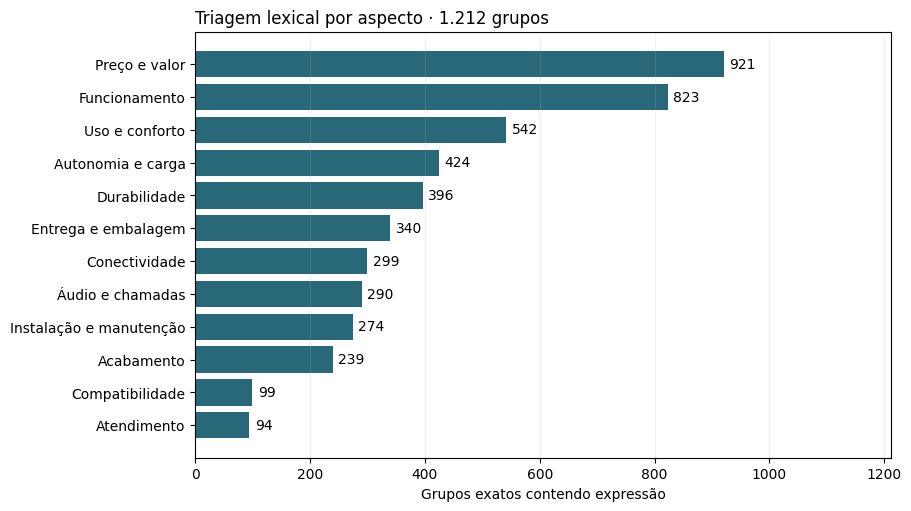

,Grupos com candidato,Pares com candidato,Produtos com candidato
Preço e valor,921,1062,1049
Funcionamento,823,937,927
Uso e conforto,542,588,586
Autonomia e carga,424,542,527
Durabilidade,396,456,444
Entrega e embalagem,340,383,378
Conectividade,299,365,362
Áudio e chamadas,290,366,364
Instalação e manutenção,274,306,305
Acabamento,239,268,264


In [27]:
# Busca de candidatos em título e conteúdo. Uma expressão pode ter outro objeto.
taxonomia = {
    "Funcionamento": (r"\b(?:working|works?|stopped|faulty|malfunction)\b","Produto ou componente; genérico sem objeto"),
    "Acabamento": (r"\b(?:build quality|material quality|finish|scratch(?:es)?|stains?)\b","Superfície, material ou estado na entrega"),
    "Durabilidade": (r"\b(?:durab\w*|sturdy|broke|breaks?|stopped working)\b","Separar aparência, previsão e experiência"),
    "Compatibilidade": (r"\b(?:compatib\w*|usb[- ]?[ac]|micro[- ]?(?:usb|b)|lightning|3\.5\s*mm)\b","Conector, dispositivo e variante"),
    "Conectividade": (r"\b(?:connect\w*|bluetooth|wi-?fi|pairing|sync\w*)\b","Separar conexão elétrica, sem fio e sincronização"),
    "Áudio e chamadas": (r"\b(?:sound|audio|bass|mic|microphone|calls?|volume)\b","Distinguir música, microfone, FM e chamadas"),
    "Autonomia e carga": (r"\b(?:battery|batteries|charg(?:e[rs]?|ing)|mah)\b","Cobrança monetária e aparelho conectado exigem revisão"),
    "Uso e conforto": (r"\b(?:easy to use|comfort\w*|fitting|fit|keypad|weight)\b","Encaixe, peso e manuseio variam por função"),
    "Instalação e manutenção": (r"\b(?:install\w*|cleaning|easy to clean|maintenance|cartridge|filter replacement)\b","Distinguir montagem, limpeza e serviço"),
    "Preço e valor": (r"\b(?:value for money|worth (?:for )?(?:the )?money|worth the price|not worth|budget|price)\b","Inclui negação e preço sem opinião"),
    "Entrega e embalagem": (r"\b(?:deliver\w*|packag\w*|packed|courier)\b","Serviço logístico ou embalagem, com contexto"),
    "Atendimento": (r"\b(?:customer (?:care|service|support)|service (?:person|cent[er]+|request)|good service|after[- ]sales)\b","Serviço distinto do funcionamento"),
}
taxonomia_quadro = pd.DataFrame.from_dict(taxonomia,orient="index",columns=["Regra","Ambiguidade"])
buscas = list(taxonomia)
def marcar_aspectos(textos_busca):
    return pd.DataFrame({tema:textos_busca.str.contains(regra,case=False,regex=True,na=False)
        for tema,(regra,_) in taxonomia.items()},index=textos_busca.index)
grupos_aspectos = corpus[["grupo_textual_id"]].join(marcar_aspectos(corpus.texto_busca))
assert grupos_aspectos.grupo_textual_id.is_unique
pares_aspectos = pares_pg.merge(grupos_aspectos,on="grupo_textual_id",validate="many_to_one")
flags_aspectos = pares_aspectos.groupby("product_id")[buscas].any()
resumo_aspectos = pd.DataFrame({"Grupos com candidato":grupos_aspectos[buscas].sum(),
    "Pares com candidato":pares_aspectos[buscas].sum(),"Produtos com candidato":flags_aspectos.sum()})
assert len(flags_aspectos)==1351 and len(pares_aspectos)==1370
display(taxonomia_quadro[["Ambiguidade"]].style.set_properties(**{"white-space":"normal","max-width":"420px"}))
fig,ax=plt.subplots(figsize=(9,5),layout="constrained")
q=resumo_aspectos["Grupos com candidato"].sort_values()
ax.barh(q.index,q,color="#286879")
ax.bar_label(ax.containers[0],padding=4)
ax.set(xlabel="Grupos exatos contendo expressão",xlim=(0,1212))
ax.set_title("Triagem lexical por aspecto · 1.212 grupos",loc="left")
ax.grid(axis="x",alpha=.2)
plt.show()
display(resumo_aspectos.sort_values("Grupos com candidato",ascending=False))

A taxonomia ampliada serve à triagem. Compatibilidade e áudio têm aplicação dependente da função. Carga pode se referir ao aparelho conectado e entrega ao serviço. Um acerto lexical inclui negações, citações e referências a outros produtos. A leitura precisa localizar o objeto antes de atribuir polaridade.

In [28]:
def localizar_excerto(produto, campo, excerto, ocorrencia=None):
    if campo == "about_product":
        p=p_canon.set_index("product_id").loc[produto]
        fonte=o_canon.set_index("ocorrencia_id").loc[p.ocorrencia_id_referencia]
        oc=p.ocorrencia_id_referencia
    else:
        fontes=o_canon.loc[o_canon.product_id.eq(produto)].sort_values("source_index")
        if ocorrencia is not None:
            fontes=fontes.loc[fontes.ocorrencia_id.eq(ocorrencia)]
        fonte=fontes.loc[fontes[campo].str.contains(excerto,regex=False,case=False,na=False)].iloc[0]
        oc=fonte.ocorrencia_id
    achado=re.search(re.escape(excerto),fonte[campo],flags=re.IGNORECASE)
    assert achado is not None and fonte.product_id==produto
    inicio,fim=achado.span()
    return oc,fonte.grupo_textual_id,inicio,fim,fonte[campo][inicio:fim]

def montar_evidencias(selecoes):
    colunas=["Produto","Aspecto","Objeto","Leitura","Campo","Ocorrência","Grupo","Início","Fim","Excerto"]
    return pd.DataFrame([(p,a,o,l,c,*localizar_excerto(p,c,e)) for p,a,o,l,c,e in selecoes],columns=colunas)

def exibir_trechos(quadro):
    display(quadro.drop(columns="Grupo").style.hide(axis="index").format(escape="html")
        .set_properties(**{"overflow-wrap":"anywhere","max-width":"290px","white-space":"normal"}))

In [29]:
auditoria_trechos = montar_evidencias([('B08DPLCM6T', 'Imagem', 'televisor', 'Favorável', 'review_content', 'Picture quality is awesome.'), ('B08DPLCM6T', 'Áudio', 'televisor', 'Desfavorável', 'review_content', 'sound quality was poor.'), ('B07B88KQZ8', 'Áudio', 'caixa de som', 'Favorável', 'review_content', 'awesome sound more than expected'), ('B07B88KQZ8', 'Microfone', 'caixa de som', 'Desfavorável', 'review_content', 'the mic feature is not that good.'), ('B00B7GKXMG', 'Uso', 'produto', 'Favorável', 'review_content', 'light weight easy to use'), ('B00B7GKXMG', 'Preço e valor', 'produto', 'Desfavorável', 'review_content', 'is not worth for the value'), ('B00B7GKXMG', 'Preço e valor', 'produto', 'Favorável', 'review_content', 'Value for money @600₹'), ('B0B3MMYHYW', 'Autonomia e carga', 'cobrança de serviço', 'Outro assunto', 'review_content', 'charging money'), ('B09XB8GFBQ', 'Acabamento', 'tela', 'Desfavorável', 'review_content', 'display is very poor quality'), ('B09XJ1LM7R', 'Funcionamento', 'comando liga/desliga', 'Desfavorável', 'review_content', 'tv on off not working')])
exibir_trechos(auditoria_trechos)

Produto,Aspecto,Objeto,Leitura,Campo,Ocorrência,Início,Fim,Excerto
B08DPLCM6T,Imagem,televisor,Favorável,review_content,OC-000020,182,209,Picture quality is awesome.
B08DPLCM6T,Áudio,televisor,Desfavorável,review_content,OC-000020,56,79,sound quality was poor.
B07B88KQZ8,Áudio,caixa de som,Favorável,review_content,OC-000731,764,796,awesome sound more than expected
B07B88KQZ8,Microfone,caixa de som,Desfavorável,review_content,OC-000731,1238,1271,the mic feature is not that good.
B00B7GKXMG,Uso,produto,Favorável,review_content,OC-001338,4,28,light weight easy to use
B00B7GKXMG,Preço e valor,produto,Desfavorável,review_content,OC-001338,33,59,is not worth for the value
B00B7GKXMG,Preço e valor,produto,Favorável,review_content,OC-001338,155,176,Value for money @600₹
B0B3MMYHYW,Autonomia e carga,cobrança de serviço,Outro assunto,review_content,OC-000039,2027,2041,charging money
B09XB8GFBQ,Acabamento,tela,Desfavorável,review_content,OC-000351,11,39,display is very poor quality
B09XJ1LM7R,Funcionamento,comando liga/desliga,Desfavorável,review_content,OC-000156,0,21,tv on off not working


Nos grupos revisados, o televisor combina elogio à imagem e crítica ao som. A caixa de som combina elogio ao áudio e ressalva ao microfone. No bloco do produto B00B7GKXMG há juízos favorável e desfavorável sobre valor, o que sustenta a leitura **mista no aspecto**, sem atribuir as frases à mesma pessoa. O contexto charging money é cobrança de serviço. Ele é um falso positivo para carregamento elétrico e ajuda a definir uma exclusão para o piloto.

Trechos mostram problemas observados de áudio, funcionamento e acabamento. A seleção dirigida e a falta de avaliação independente impedem estimar qual reclamação é mais frequente. As contagens anteriores ordenam assuntos candidatos, com denominadores de grupo, par ou produto.

## 5 — O que os oito casos prioritários revelam?

Os oito IDs vêm da seleção final do Notebook 03. Para o celular, acrescentamos o produto do mesmo caminho mais próximo em preço após excluir IDs que compartilham bloco com o alvo. O desempate usa o ID. O Motorola de outra cor compartilha o mesmo grupo e fica fora da comparação independente de excertos. A comparação descreve dois blocos distintos sem supor independência entre consumidores.

In [30]:
ids_n03 = ["B01LONQBDG","B071SDRGWL","B07JQKQ91F","B01F25X6RQ",
           "B076VQS87V","B009P2L7CO","B09JS562TP","B096NTB9XT"]
principal = visao_textual.set_index("product_id").loc["B09JS562TP"]
mesmo_caminho = visao_textual.loc[visao_textual.category_original.eq(principal.category_original)].copy()
grupos_alvo = set(pares_pg.loc[pares_pg.product_id.eq(principal.name),"grupo_textual_id"])
ids_reutilizados = pares_pg.loc[pares_pg.grupo_textual_id.isin(grupos_alvo),"product_id"]
elegiveis = mesmo_caminho.loc[~mesmo_caminho.product_id.isin(ids_reutilizados)].copy()
elegiveis["Distância INR"] = (elegiveis.discounted_price_num-principal.discounted_price_num).abs()
comparador_celular = elegiveis.sort_values(["Distância INR","product_id"]).iloc[0].product_id
assert comparador_celular=="B09YDFDVNS"
casos = visao_textual.set_index("product_id").loc[[*ids_n03,comparador_celular]].copy()
assert len(casos)==9 and casos.grupos_textuais.eq(1).all()
for a,b in [(0,1),(2,3),(4,5),(6,8)]:
    assert casos.iloc[a].category_original==casos.iloc[b].category_original
casos["Estabilidade"] = casos.perfil_persistente_n2.map({True:"Persistiu",False:"Mudou"})
display(casos[["product_name","category_original","perfil_completo","perfil_n2","Estabilidade"]].style
    .set_properties(**{"overflow-wrap":"anywhere","max-width":"330px"}))
display(casos[["actual_price_num","discounted_price_num","discount_percentage_num","rating_num",
    "rating_count_num","grupos_textuais"]].rename(columns={"actual_price_num":"Original (INR)",
    "discounted_price_num":"Com desconto (INR)","discount_percentage_num":"Desconto (%)",
    "rating_num":"Nota","rating_count_num":"Contagem informada"}))

,product_name,category_original,perfil_completo,perfil_n2,Estabilidade
product_id,,,,,
B01LONQBDG,AmazonBasics USB Type-C to Micro-B 2.0 Cable - 6 Inches (15.2 Centimeters) - White,Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,A,A,Persistiu
B071SDRGWL,"boAt Type-c A400 Type-c to USB A Cable for All Type C Phones (Lg nexus 5x), 1Mtr(Black)",Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,B,B,Persistiu
B07JQKQ91F,"JBL C50HI, Wired in Ear Headphones with Mic, One Button Multi-Function Remote, Lightweight & Comfortable fit (Black)","Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear",A,Empate,Mudou
B01F25X6RQ,Samsung Ehs64 Ehs64Avfwecinu Hands-Free Wired In Ear Earphones With Mic With Remote Note (White),"Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear",B,Alta/baixa,Mudou
B076VQS87V,Syska SDI-07 1000 W Stellar with Golden American Heritage Soleplate Dry Iron (Blue),"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|Irons|DryIrons",Alta/baixa,Alta/baixa,Persistiu
B009P2L7CO,"Bajaj DHX-9 1000W Heavy Weight Dry Iron with Advance Soleplate and Anti-Bacterial German Coating Technology, Ivory","Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|Irons|DryIrons",B,B,Persistiu
B09JS562TP,"Motorola a10 Dual Sim keypad Mobile with 1750 mAh Battery, Expandable Storage Upto 32GB, Wireless FM with Recording - Rose Gold",Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|BasicMobiles,A,Baixa/baixa,Mudou
B096NTB9XT,"Aquaguard Aura RO+UV+UF+Taste Adjuster(MTDS) with Active Copper & Zinc 7L water purifier,8 stages of purification,suitable for borewell,tanker,municipal water(Black) from Eureka Forbes",Home&Kitchen|Kitchen&HomeAppliances|WaterPurifiers&Accessories|WaterFilters&Purifiers,A,A,Persistiu
B09YDFDVNS,"Nokia 105 Plus Single SIM, Keypad Mobile Phone with Wireless FM Radio, Memory Card Slot and MP3 Player | Red",Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|BasicMobiles,A,A,Persistiu


,Original (INR),Com desconto (INR),Desconto (%),Nota,Contagem informada,grupos_textuais
product_id,,,,,,
B01LONQBDG,899.0,349.0,61.0,4.1,14896,1
B071SDRGWL,699.0,349.0,50.0,4.3,20850,1
B07JQKQ91F,999.0,499.0,50.0,3.9,92995,1
B01F25X6RQ,499.0,499.0,0.0,4.2,31539,1
B076VQS87V,799.0,457.0,43.0,4.3,1868,1
B009P2L7CO,1920.0,1099.0,43.0,4.2,9772,1
B09JS562TP,1630.0,1399.0,14.0,4.0,9378,1
B096NTB9XT,24500.0,15999.0,35.0,4.0,11206,1
B09YDFDVNS,1699.0,1324.0,22.0,4.0,128311,1


### 5.1 — Cabos USB

In [31]:
evidencias_1 = montar_evidencias([('B01LONQBDG', 'Conectores e sincronização', 'cabo', 'Anunciado', 'about_product', 'Offers reliable connectivity for easy charging or syncing'), ('B01LONQBDG', 'Compatibilidade', 'cabo e telefones', 'Favorável', 'review_content', 'You can easily transfer files between two android phones, one with micro USB port and the other with USB C.'), ('B01LONQBDG', 'Acabamento', 'cabo', 'Desfavorável', 'review_content', 'it had yellow stains on it'), ('B01LONQBDG', 'Espessura', 'cabo', 'Desfavorável', 'review_content', 'The cable could have been thicker.'), ('B071SDRGWL', 'Durabilidade e sincronização', 'cabo', 'Anunciado', 'about_product', 'Support The Maximum 3A Fast Charging And The Speed Of Data Sync Up To 480 Mbps'), ('B071SDRGWL', 'Durabilidade', 'cabo', 'Anunciado', 'about_product', 'For Reinforcement And Added Durability'), ('B071SDRGWL', 'Durabilidade', 'cabo', 'Favorável', 'review_content', 'it almost last three years post heavy usage'), ('B071SDRGWL', 'Carregamento', 'cabo e aparelho', 'Favorável', 'review_content', 'enables Fast Charging for Samsung M21 as well as M33 5G 24 W seeking phones'), ('B071SDRGWL', 'Comprimento', 'variante do cabo', 'Insuficiente', 'review_content', '2 metre cable length helpful')])
exibir_trechos(evidencias_1)

Produto,Aspecto,Objeto,Leitura,Campo,Ocorrência,Início,Fim,Excerto
B01LONQBDG,Conectores e sincronização,cabo,Anunciado,about_product,OC-000295,127,184,Offers reliable connectivity for easy charging or syncing
B01LONQBDG,Compatibilidade,cabo e telefones,Favorável,review_content,OC-000295,175,282,"You can easily transfer files between two android phones, one with micro USB port and the other with USB C."
B01LONQBDG,Acabamento,cabo,Desfavorável,review_content,OC-000295,396,422,it had yellow stains on it
B01LONQBDG,Espessura,cabo,Desfavorável,review_content,OC-000295,1385,1419,The cable could have been thicker.
B071SDRGWL,Durabilidade e sincronização,cabo,Anunciado,about_product,OC-000140,0,78,Support The Maximum 3A Fast Charging And The Speed Of Data Sync Up To 480 Mbps
B071SDRGWL,Durabilidade,cabo,Anunciado,about_product,OC-000140,276,314,For Reinforcement And Added Durability
B071SDRGWL,Durabilidade,cabo,Favorável,review_content,OC-000140,266,309,it almost last three years post heavy usage
B071SDRGWL,Carregamento,cabo e aparelho,Favorável,review_content,OC-000140,390,465,enables Fast Charging for Samsung M21 as well as M33 5G 24 W seeking phones
B071SDRGWL,Comprimento,variante do cabo,Insuficiente,review_content,OC-000140,467,495,2 metre cable length helpful


O primeiro cabo anuncia USB-C para Micro-B e o segundo USB-A para USB-C. O preço igual e o caminho comum permitem comparar a função ampla. Os conectores limitam a equivalência. Há relato de transferência no primeiro junto de manchas e ressalva à espessura. No segundo, há relatos de resistência e carga em modelos específicos. A menção a dois metros merece conferir a variante de um metro anunciada antes de atribuir o resultado à especificação.

### 5.2 — Fones in-ear

In [32]:
evidencias_2 = montar_evidencias([('B07JQKQ91F', 'Graves', 'fone', 'Anunciado', 'about_product', 'High Clean Bass'), ('B07JQKQ91F', 'Conforto', 'fone', 'Anunciado', 'about_product', 'Lightweight and comfortable'), ('B07JQKQ91F', 'Encaixe', 'fone', 'Favorável', 'review_content', 'Fitting in ear is perfect'), ('B07JQKQ91F', 'Graves', 'fone', 'Desfavorável', 'review_content', 'the bass was not up to mark'), ('B07JQKQ91F', 'Durabilidade', 'fone', 'Insuficiente', 'review_content', "I can't comment on its durability"), ('B07JQKQ91F', 'Funcionamento', 'fone', 'Desfavorável', 'review_content', 'Unable to hear after, 8 months'), ('B01F25X6RQ', 'Conexão', 'fone', 'Anunciado', 'about_product', 'Headphone Jack: 3.5mm'), ('B01F25X6RQ', 'Som', 'fone', 'Favorável', 'review_content', 'The sound quality is excellent for the price'), ('B01F25X6RQ', 'Material', 'fone', 'Desfavorável', 'review_content', "the material quality isn't good"), ('B01F25X6RQ', 'Microfone', 'fone', 'Favorável', 'review_content', 'mic works well during the call.'), ('B01F25X6RQ', 'Graves', 'fone', 'Desfavorável', 'review_content', 'Less bass'), ('B01F25X6RQ', 'Graves', 'fone', 'Favorável', 'review_content', 'Treble and bass are balanced well.')])
exibir_trechos(evidencias_2)

Produto,Aspecto,Objeto,Leitura,Campo,Ocorrência,Início,Fim,Excerto
B07JQKQ91F,Graves,fone,Anunciado,about_product,OC-000602,218,233,High Clean Bass
B07JQKQ91F,Conforto,fone,Anunciado,about_product,OC-000602,20,47,Lightweight and comfortable
B07JQKQ91F,Encaixe,fone,Favorável,review_content,OC-000602,154,179,Fitting in ear is perfect
B07JQKQ91F,Graves,fone,Desfavorável,review_content,OC-000602,1543,1570,the bass was not up to mark
B07JQKQ91F,Durabilidade,fone,Insuficiente,review_content,OC-000602,58,91,I can't comment on its durability
B07JQKQ91F,Funcionamento,fone,Desfavorável,review_content,OC-000602,424,454,"Unable to hear after, 8 months"
B01F25X6RQ,Conexão,fone,Anunciado,about_product,OC-000467,42,63,Headphone Jack: 3.5mm
B01F25X6RQ,Som,fone,Favorável,review_content,OC-000467,0,44,The sound quality is excellent for the price
B01F25X6RQ,Material,fone,Desfavorável,review_content,OC-000467,85,116,the material quality isn't good
B01F25X6RQ,Microfone,fone,Favorável,review_content,OC-000467,531,562,mic works well during the call.


No JBL, o encaixe elogiado se alinha à descrição de conforto. A promessa de graves encontra ressalva no relato, que também compara outro modelo. Um trecho explicita falta de tempo para avaliar durabilidade e outro relata perda de áudio após oito meses. O Samsung recebe elogios a som e microfone e críticas ao material, apesar de estar em B no corte oficial. Graves aparecem com sinais opostos no mesmo bloco. O preço de INR 499 é comum, mas as diferenças de desconto e de perfil auxiliar impedem uma explicação simples.

### 5.3 — Ferros a seco

In [33]:
evidencias_3 = montar_evidencias([('B076VQS87V', 'Potência e cabo', 'ferro', 'Anunciado', 'about_product', 'Swivel Cord, Dry Iron 1000W'), ('B076VQS87V', 'Cabo', 'ferro', 'Desfavorável', 'review_content', 'Cord is too short'), ('B076VQS87V', 'Uso', 'ferro', 'Favorável', 'review_content', 'Like the product great quality and easy to use'), ('B076VQS87V', 'Peso', 'ferro', 'Favorável', 'review_content', 'Light weight working good'), ('B076VQS87V', 'Acabamento', 'ferro', 'Desfavorável', 'review_title', 'There was one scratch on the surface which was hide under the sticker'), ('B009P2L7CO', 'Peso e uso', 'ferro', 'Anunciado', 'about_product', 'Heavy weight iron for easy ironing.'), ('B009P2L7CO', 'Aquecimento', 'ferro', 'Anunciado', 'about_product', 'Multiple temprature levels'), ('B009P2L7CO', 'Peso', 'ferro', 'Insuficiente', 'review_content', 'Weight is reduced a bit'), ('B009P2L7CO', 'Entrega', 'estado na entrega', 'Desfavorável', 'review_content', 'Damage product deliveredTwo times'), ('B009P2L7CO', 'Funcionamento', 'ferro', 'Favorável', 'review_content', 'works fine even after 4 months')])
exibir_trechos(evidencias_3)

Produto,Aspecto,Objeto,Leitura,Campo,Ocorrência,Início,Fim,Excerto
B076VQS87V,Potência e cabo,ferro,Anunciado,about_product,OC-001448,73,100,"Swivel Cord, Dry Iron 1000W"
B076VQS87V,Cabo,ferro,Desfavorável,review_content,OC-001448,0,17,Cord is too short
B076VQS87V,Uso,ferro,Favorável,review_content,OC-001448,51,97,Like the product great quality and easy to use
B076VQS87V,Peso,ferro,Favorável,review_content,OC-001448,110,135,Light weight working good
B076VQS87V,Acabamento,ferro,Desfavorável,review_title,OC-001448,141,210,There was one scratch on the surface which was hide under the sticker
B009P2L7CO,Peso e uso,ferro,Anunciado,about_product,OC-001210,0,35,Heavy weight iron for easy ironing.
B009P2L7CO,Aquecimento,ferro,Anunciado,about_product,OC-001210,134,160,Multiple temprature levels
B009P2L7CO,Peso,ferro,Insuficiente,review_content,OC-001210,14,37,Weight is reduced a bit
B009P2L7CO,Entrega,estado na entrega,Desfavorável,review_content,OC-001210,38,71,Damage product deliveredTwo times
B009P2L7CO,Funcionamento,ferro,Favorável,review_content,OC-001210,72,102,works fine even after 4 months


No Syska há elogios à facilidade e ao peso, com ressalva ao comprimento do cabo e uma marca descrita no título. No Bajaj, o anúncio enfatiza peso e ajustes de temperatura. O relato sobre peso tem referência incerta e há indicação de funcionamento após quatro meses. A menção a produto danificado na entrega precisa de investigação logística própria. Desconto igual é contexto para comparar atributos, sem explicar a diferença de INR 642.

### 5.4 — Celular básico

In [34]:
evidencias_4 = montar_evidencias([('B09JS562TP', 'Autonomia', 'celular', 'Anunciado', 'about_product', '1750mAh battery gives you twice the power of other phones'), ('B09JS562TP', 'Áudio', 'celular', 'Anunciado', 'about_product', 'Experience loud and crystal clear sound'), ('B09JS562TP', 'Autonomia', 'celular', 'Favorável', 'review_content', 'Battery lasted for 15+ days with low-medium usage.'), ('B09JS562TP', 'Chamadas', 'celular', 'Desfavorável', 'review_content', 'rating everything is okay except voice sound during call'), ('B09JS562TP', 'Carregador', 'acessório', 'Desfavorável', 'review_content', 'charger quality bad'), ('B09JS562TP', 'Áudio FM', 'celular', 'Desfavorável', 'review_content', 'There is some disturbance in the sound While using wireless FM'), ('B09YDFDVNS', 'Uso', 'celular', 'Anunciado', 'about_product', 'familiar and easy to use'), ('B09YDFDVNS', 'Teclado', 'celular', 'Desfavorável', 'review_content', 'it takes more than 1 attempt sometimes to perform OK action.'), ('B09YDFDVNS', 'Autonomia', 'celular', 'Favorável', 'review_content', 'Superb battery life for more then 3 days'), ('B09YDFDVNS', 'Autonomia', 'celular', 'Desfavorável', 'review_content', 'Battery backup bad')])
exibir_trechos(evidencias_4)

Produto,Aspecto,Objeto,Leitura,Campo,Ocorrência,Início,Fim,Excerto
B09JS562TP,Autonomia,celular,Anunciado,about_product,OC-000456,104,161,1750mAh battery gives you twice the power of other phones
B09JS562TP,Áudio,celular,Anunciado,about_product,OC-000456,350,389,Experience loud and crystal clear sound
B09JS562TP,Autonomia,celular,Favorável,review_content,OC-000456,196,246,Battery lasted for 15+ days with low-medium usage.
B09JS562TP,Chamadas,celular,Desfavorável,review_content,OC-000456,0,56,rating everything is okay except voice sound during call
B09JS562TP,Carregador,acessório,Desfavorável,review_content,OC-000456,118,137,charger quality bad
B09JS562TP,Áudio FM,celular,Desfavorável,review_content,OC-000456,419,481,There is some disturbance in the sound While using wireless FM
B09YDFDVNS,Uso,celular,Anunciado,about_product,OC-000442,41,65,familiar and easy to use
B09YDFDVNS,Teclado,celular,Desfavorável,review_content,OC-000442,819,879,it takes more than 1 attempt sometimes to perform OK action.
B09YDFDVNS,Autonomia,celular,Favorável,review_content,OC-000442,118,158,Superb battery life for more then 3 days
B09YDFDVNS,Autonomia,celular,Desfavorável,review_content,OC-000442,880,898,Battery backup bad


O Motorola relata autonomia sob uso leve a moderado, mas distingue áudio de chamadas e FM. A avaliação do carregador trata de um acessório. O Nokia comparável traz experiência favorável e desfavorável de bateria, além de dificuldade com a tecla central. O contraste sugere testar autonomia sob protocolos comparáveis e separar usabilidade do teclado, chamadas e entretenimento. A mudança do perfil oficial para o corte de ramo contextualiza a prioridade do Motorola.

### 5.5 — Purificador de água

In [35]:
evidencias_5 = montar_evidencias([('B096NTB9XT', 'Instalação', 'purificador', 'Anunciado', 'about_product', 'the purifier can be easily wall mounted or kept on the counter top.'), ('B096NTB9XT', 'Indicador', 'purificador', 'Anunciado', 'about_product', 'LED indication alerts when tank is full'), ('B096NTB9XT', 'Sabor', 'água', 'Favorável', 'review_content', 'taste is also good'), ('B096NTB9XT', 'Instalação', 'purificador', 'Favorável', 'review_content', 'Esy to install'), ('B096NTB9XT', 'Entrada e indicador', 'purificador', 'Desfavorável', 'review_content', 'the inlet stops taking water but the indicator shows tank filling!'), ('B096NTB9XT', 'Atendimento', 'serviço', 'Favorável', 'review_content', 'Good service')])
exibir_trechos(evidencias_5)

Produto,Aspecto,Objeto,Leitura,Campo,Ocorrência,Início,Fim,Excerto
B096NTB9XT,Instalação,purificador,Anunciado,about_product,OC-001326,622,689,The purifier can be easily wall mounted or kept on the counter top.
B096NTB9XT,Indicador,purificador,Anunciado,about_product,OC-001326,739,778,LED indication alerts when tank is full
B096NTB9XT,Sabor,água,Favorável,review_content,OC-001326,38,56,taste is also good
B096NTB9XT,Instalação,purificador,Favorável,review_content,OC-001326,894,908,Esy to install
B096NTB9XT,Entrada e indicador,purificador,Desfavorável,review_content,OC-001326,297,363,the inlet stops taking water but the indicator shows tank filling!
B096NTB9XT,Atendimento,serviço,Favorável,review_content,OC-001326,0,12,Good service


O produto anuncia instalação flexível e indicadores. O bloco elogia sabor e instalação e descreve interrupção na entrada com indicação de enchimento. Essa ocorrência merece consulta ao suporte e verificação do sensor e das condições de instalação. Sabor é experiência relatada. Qualidade sanitária, incidência de falha, termos de serviço e justificativa do preço exigem dados técnicos e operacionais.

## 6 — O que permanece quando cruzamos relatos e atributos comerciais?

O produto é a unidade das proporções. Um produto elegível tem bloco disponível e conta uma vez por aspecto, ainda que haja mais de uma ocorrência. O corte de perfil vem do universo completo. Faixas de preço original usam os quartis do catálogo. O desconto local compara postos no ramo. Células pequenas são descritivas e orientam a leitura de casos.

### Perfis relativos e integração temática

Como as menções se distribuem nos contrastes de A04? A unidade comercial é um produto. A e B indicam nota abaixo e acima da mediana local, ambos com contagem igual ou superior à mediana. Empates e ausências permanecem separados.

In [36]:
catalogo = tabelas["produtos"].copy()
perfis_c05 = catalogo.loc[catalogo.categoria_nivel_1.isin(["Electronics", "Computers&Accessories", "Home&Kitchen"])].copy()
for campo in ["rating_num", "rating_count_num"]:
    perfis_c05["mediana_" + campo] = perfis_c05.groupby("categoria_nivel_1")[campo].transform("median")
perfis_c05["perfil"] = "Contagem inferior; nota diferente"
perfis_c05.loc[perfis_c05.rating_num.eq(perfis_c05.mediana_rating_num), "perfil"] = "Empate"
for operador, nome in [("lt", "A"), ("gt", "B")]:
    selecao = getattr(perfis_c05.rating_num, operador)(perfis_c05.mediana_rating_num) & perfis_c05.rating_count_num.ge(perfis_c05.mediana_rating_count_num)
    perfis_c05.loc[selecao, "perfil"] = nome
perfis_c05.loc[perfis_c05[["rating_num", "rating_count_num"]].isna().any(axis=1), "perfil"] = "Ausência"
display(perfis_c05.groupby("categoria_nivel_1")[["mediana_rating_num", "mediana_rating_count_num"]].first())
display(pd.crosstab(perfis_c05.categoria_nivel_1, perfis_c05.perfil))
assert perfis_c05.perfil.value_counts()[["A", "B", "Empate"]].tolist() == [212, 299, 228]

,mediana_rating_num,mediana_rating_count_num
categoria_nivel_1,,
Computers&Accessories,4.2,7317.0
Electronics,4.1,9129.5
Home&Kitchen,4.1,2305.5


perfil,A,Ausência,B,Contagem inferior; nota diferente,Empate
categoria_nivel_1,,,,,
Computers&Accessories,59,2,90,166,58
Electronics,75,0,108,220,87
Home&Kitchen,78,1,101,185,83


### Associação sem multiplicar o catálogo

A presença significa ao menos um grupo com expressão; não mede intensidade ou aprovação. A relação conserva os IDs originais para consulta.

In [37]:
temas_c05 = [c for c in mencoes_grupos.columns if c != "grupo_textual_id" and "candidato" not in c] + list(expressoes_adicionais)
associacao_c05 = relacoes_textuais.merge(mencoes_grupos[["grupo_textual_id"] + temas_c05[:2]], on="grupo_textual_id", validate="many_to_one").merge(mencoes_adicionais, on="grupo_textual_id", validate="many_to_one")
visao_c05 = catalogo.merge(associacao_c05.groupby("product_id")[temas_c05].any(), on="product_id", how="left", validate="one_to_one")
assert len(visao_c05) == 1351 and len(associacao_c05) == 1370
assert visao_c05[temas_c05].notna().all().all()
print("Cobertura:", len(visao_c05), "produtos; vínculos:", len(associacao_c05))
display(visao_c05[["product_id", "categoria_nivel_1"] + temas_c05].head())
contrastes_c05 = perfis_c05.loc[perfis_c05.perfil.isin(["A", "B"])].merge(visao_c05[["product_id"] + temas_c05], on="product_id", validate="one_to_one")

Cobertura: 1351 produtos; vínculos: 1370


,product_id,categoria_nivel_1,Bateria,Som e áudio,Referência a value for money,Referência a facilidade de uso/instalação/limpeza
0,B002PD61Y4,Computers&Accessories,False,False,False,False
1,B002SZEOLG,Computers&Accessories,True,False,False,True
2,B003B00484,Electronics,True,False,False,False
3,B003L62T7W,Computers&Accessories,False,False,False,False
4,B004IO5BMQ,Computers&Accessories,True,False,False,False


### Frequências dentro de cada categoria e perfil

Os denominadores incluem todos os produtos do perfil. As famílias se sobrepõem e não devem ser somadas.

In [38]:
for dimensoes in [["categoria_nivel_1", "perfil"], ["perfil"]]:
    contagens_c05 = contrastes_c05.groupby(dimensoes)[temas_c05].sum()
    denominadores_c05 = contrastes_c05.groupby(dimensoes).size()
    tabela_c05 = contagens_c05.stack().rename("Com menção").to_frame()
    tabela_c05["Denominador"] = denominadores_c05.reindex(tabela_c05.index.droplevel(-1)).to_numpy()
    tabela_c05["Percentual"] = 100 * tabela_c05["Com menção"] / tabela_c05.Denominador
    display(tabela_c05.round(2))
display(pd.crosstab(contrastes_c05.categoria_nivel_2, contrastes_c05.perfil))

Com menção  \
categoria_nivel_1     perfil                                                                 
Computers&Accessories A      Bateria                                                     8   
                             Som e áudio                                                 4   
                             Referência a value for money                               24   
                             Referência a facilidade de uso/instalação/limpeza          14   
                      B      Bateria                                                    18   
                             Som e áudio                                                 9   
                             Referência a value for money                               31   
                             Referência a facilidade de uso/instalação/limpeza          31   
Electronics           A      Bateria                                                    48   
                             Som e áudio                                                43   
                             Referência a value for money                               27   
                             Referência a facilidade de uso/instalação/limpeza           2   
                      B      Bateria                                                    41   
                             Som e áudio                                                51   
                             Referência a value for money                               41   
                             Referência a facilidade de uso/instalação/limpeza          11   
Home&Kitchen          A      Bateria                                                     4   
                             Som e áudio                                                 6   
                             Referência a value for money                               26   
                             Referência a facilidade de uso/instalação/limpeza          37   
                      B      Bateria                                                     4   
                             Som e áudio                                                 8   
                             Referência a value for money                               30   
                             Referência a facilidade de uso/instalação/limpeza          54   

                                                                                Denominador  \
categoria_nivel_1     perfil                                                                  
Computers&Accessories A      Bateria                                                     59   
                             Som e áudio                                                 59   
                             Referência a value for money                                59   
                             Referência a facilidade de uso/instalação/limpeza           59   
                      B      Bateria                                                     90   
                             Som e áudio                                                 90   
                             Referência a value for money                                90   
                             Referência a facilidade de uso/instalação/limpeza           90   
Electronics           A      Bateria                                                     75   
                             Som e áudio                                                 75   
                             Referência a value for money                                75   
                             Referência a facilidade de uso/instalação/limpeza           75   
                      B      Bateria                                                    108   
                             Som e áudio                                                108   
                             Referência a value for money                               108   
                    

Com menção  \
perfil                                                                 
A      Bateria                                                    60   
       Som e áudio                                                53   
       Referência a value for money                               77   
       Referência a facilidade de uso/instalação/limpeza          53   
B      Bateria                                                    63   
       Som e áudio                                                68   
       Referência a value for money                              102   
       Referência a facilidade de uso/instalação/limpeza          96   

                                                          Denominador  \
perfil                                                                  
A      Bateria                                                    212   
       Som e áudio                                                212   
       Referência a value for money                               212   
       Referência a facilidade de uso/instalação/limpeza          212   
B      Bateria                                                    299   
       Som e áudio                                                299   
       Referência a value for money                               299   
       Referência a facilidade de uso/instalação/limpeza          299   

                                                          Percentual  
perfil                                                                
A      Bateria                                                  28.3  
       Som e áudio                                              25.0  
       Referência a value for money                            36.32  
       Referência a facilidade de uso/instalação/limpeza        25.0  
B      Bateria                                                 21.07  
       Som e áudio                                             22.74  
       Referência a value for money                            34.11  
       Referência a facilidade de uso/instalação/limpeza       32.11

perfil,A,B
categoria_nivel_2,,
Accessories,1,10
Accessories&Peripherals,48,61
Cameras&Photography,3,6
Components,0,2
CraftMaterials,1,6
ExternalDevices&DataStorage,1,14
GeneralPurposeBatteries&BatteryChargers,1,7
"Headphones,Earbuds&Accessories",25,6
"Heating,Cooling&AirQuality",18,17


### Comparação por função e sensibilidade

Grupo,Perfil,Menção,n perfil,n B,Com menção perfil,Com menção B,% perfil,% B,Diferença pp
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,Bateria,32,22,0,7,0.00,31.82,-31.82
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,Som e áudio,32,22,0,1,0.00,4.55,-4.55
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,Referência a value for money,32,22,13,5,40.62,22.73,17.90
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,Referência a facilidade de uso/instalação/limpeza,32,22,6,1,18.75,4.55,14.20
"Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions",Alta/baixa,Bateria,30,18,0,0,0.00,0.00,0.00
"Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions",Alta/baixa,Som e áudio,30,18,29,18,96.67,100.00,-3.33
"Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions",Alta/baixa,Referência a value for money,30,18,12,5,40.00,27.78,12.22
"Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions",Alta/baixa,Referência a facilidade de uso/instalação/limpeza,30,18,5,3,16.67,16.67,0.00
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,A,Bateria,23,22,0,7,0.00,31.82,-31.82
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,A,Som e áudio,23,22,0,1,0.00,4.55,-4.55


Grupo,Perfil,Menção,n perfil_oficial,n perfil_persistente,Diferença pp_oficial,Diferença pp_persistente
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,A,Bateria,23,23.00,-31.82,-31.82
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,A,Som e áudio,23,23.00,-4.55,-4.55
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,A,Referência a value for money,23,23.00,3.36,3.36
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,A,Referência a facilidade de uso/instalação/limpeza,23,23.00,-0.20,-0.20
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,Bateria,32,28.00,-31.82,-31.82
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,Som e áudio,32,28.00,-4.55,-4.55
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,Referência a value for money,32,28.00,17.90,23.70
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,Referência a facilidade de uso/instalação/limpeza,32,28.00,14.20,16.88


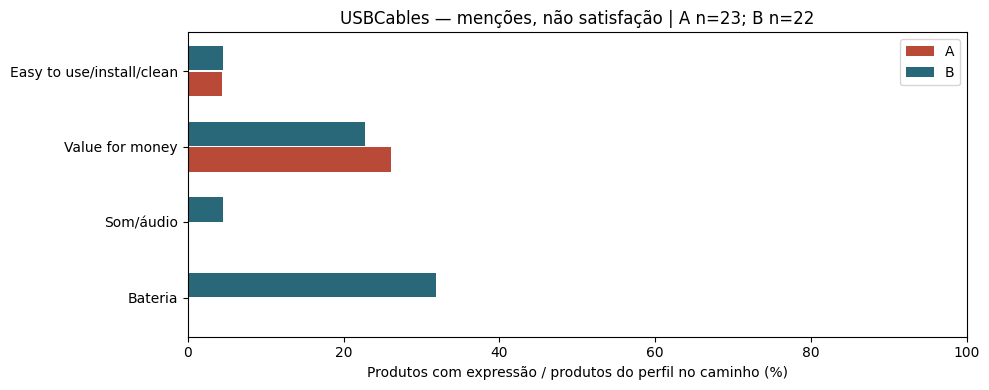

In [39]:
contrastes_caminho=contrastes_locais(visao_textual)
contrastes_persistentes=contrastes_locais(visao_textual,somente_persistentes=True)
display(contrastes_caminho.sort_values(['n perfil','n B'],ascending=False).head(12)
    .style.hide(axis='index').format(precision=2).set_properties(**{'max-width':'270px','white-space':'normal','overflow-wrap':'anywhere','word-break':'break-word'}))
comparacao_sensibilidade=contrastes_caminho.merge(contrastes_persistentes,on=['Grupo','Perfil','Menção'],how='left',suffixes=('_oficial','_persistente'),validate='one_to_one')
display(comparacao_sensibilidade[['Grupo','Perfil','Menção','n perfil_oficial','n perfil_persistente','Diferença pp_oficial','Diferença pp_persistente']].head(8)
    .style.hide(axis='index').format(precision=2,na_rep='Sem comparador suficiente').set_properties(**{'max-width':'270px','white-space':'normal','overflow-wrap':'anywhere','word-break':'break-word'}))
ramo=contrastes_caminho.loc[contrastes_caminho.Grupo.str.endswith('|USBCables') & contrastes_caminho.Perfil.eq('A')]
fig,ax=plt.subplots(figsize=(10,4))
rotulos={'Bateria':'Bateria','Som e áudio':'Som/áudio','Referência a value for money':'Value for money','Referência a facilidade de uso/instalação/limpeza':'Easy to use/install/clean'}
x=range(len(ramo))
ax.barh([i-.17 for i in x],ramo['% perfil'],height=.32,label='A',color='#b84a37')
ax.barh([i+.17 for i in x],ramo['% B'],height=.32,label='B',color='#286879')
ax.set_yticks(list(x),[rotulos[v] for v in ramo.Menção]);ax.set_xlabel('Produtos com expressão / produtos do perfil no caminho (%)')
if len(ramo):ax.set_title(f'USBCables — menções, não satisfação | A n={ramo.iloc[0]["n perfil"]}; B n={ramo.iloc[0]["n B"]}')
ax.legend();ax.set_xlim(0,100);plt.tight_layout();plt.show()

Em **USBCables**, bateria aparece em 0/23 produtos A e 7/22 B: a menção pode tratar do aparelho conectado, não do cabo. Value for money fica próximo em A/B (6/23 versus 5/22), enquanto alta/baixa tem 13/32. Entre os alta/baixa persistentes no nível 2, são 13/28; a mudança de denominador amplia a diferença, sem provar melhor percepção. Em smartphones, 7/10 A e 2/13 B têm a expressão. Nenhuma dessas taxas mede aprovação: a busca inclui negações.

**Decisão:** aprofundar leitura por função e aspecto, incluindo casos sem correspondência e objetos acessórios. Evitar uma lista global de “produtos com problemas”. O piso n≥5 deixa contrastes pequenos e instáveis; não calculamos significância ou causalidade. Os seis exemplos legados acima continuam ancorando a leitura e a compatibilidade.

No diagnóstico de proximidade, 35 pares atingem cosseno≥0,90; todos já pertenciam a componentes ligados por produto/review. Permanecem 1.181 componentes, maior com quatro grupos. Isso reduz um risco de separação, mas não demonstra independência semântica. Há escrita índica em 57/1.212 grupos; a ausência desse sinal não confirma inglês, como mostram trechos romanizados.

Com expressão  \
category_original                                  perfil_completo Aspecto                        
Computers&Accessories|Accessories&Peripherals|C... A               Preço e valor             16   
                                                   Alta/baixa      Preço e valor             20   
                                                   B               Preço e valor             19   
Electronics|Headphones,Earbuds&Accessories|Head... A               Preço e valor             18   
                                                   Alta/baixa      Preço e valor              2   
                                                   B               Preço e valor              3   
Electronics|Mobiles&Accessories|Smartphones&Bas... A               Preço e valor              7   
Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Clea... A               Preço e valor              3   
                                                   Alta/baixa      Preço e valor              2   
                                                   B               Preço e valor              9   
Home&Kitchen|Kitchen&HomeAppliances|WaterPurifi... A               Preço e valor              3   
                                                   Alta/baixa      Preço e valor              3   
                                                   B               Preço e valor              1   

                                                                                  Produtos elegíveis  \
category_original                                  perfil_completo Aspecto                             
Computers&Accessories|Accessories&Peripherals|C... A               Preço e valor                  23   
                                                   Alta/baixa      Preço e valor                  32   
                                                   B               Preço e valor                  22   
Electronics|Headphones,Earbuds&Accessories|Head... A               Preço e valor                  21   
                                                   Alta/baixa      Preço e valor                   2   
                                                   B               Preço e valor                   3   
Electronics|Mobiles&Accessories|Smartphones&Bas... A               Preço e valor                   7   
Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Clea... A               Preço e valor                   3   
                                                   Alta/baixa      Preço e valor                   2   
                                                   B               Preço e valor                  12   
Home&Kitchen|Kitchen&HomeAppliances|WaterPurifi... A               Preço e valor                   4   
                                                   Alta/baixa      Preço e valor                   4   
                                                   B               Preço e valor                   3   

                                                                                      %  
category_original                                  perfil_completo Aspecto               
Computers&Accessories|Accessories&Peripherals|C... A               Preço e valor   69.6  
                                                   Alta/baixa      Preço e valor   62.5  
                                                   B               Preço e valor   86.4  
Electronics|Headphones,Earbuds&Accessories|Head... A               Preço e valor   85.7  
                                                   Alta/baixa      Preço e valor  100.0  
                                                   B               Preço e valor  100.0  
Electronics|Mobiles&Accessories|Smartphones&Bas... A               Preço e valor  100.0  
Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Clea... A               Preço e valor  100.0  
                                                   Alta/baixa      Preço e valor  100.0  
                                             

Com expressão  \
categoria_nivel_2       Faixa original Aspecto                        
Accessories&Peripherals F1             Preço e valor            103   
                        F2             Preço e valor             89   
                        F3             Preço e valor             47   
                        F4             Preço e valor              5   
Kitchen&HomeAppliances  F1             Preço e valor             42   
                        F2             Preço e valor             61   
                        F3             Preço e valor             63   
                        F4             Preço e valor             48   

                                                      Produtos elegíveis  \
categoria_nivel_2       Faixa original Aspecto                             
Accessories&Peripherals F1             Preço e valor                 131   
                        F2             Preço e valor                 115   
                        F3             Preço e valor                  56   
                        F4             Preço e valor                   5   
Kitchen&HomeAppliances  F1             Preço e valor                  52   
                        F2             Preço e valor                  87   
                        F3             Preço e valor                 102   
                        F4             Preço e valor                  67   

                                                          %  
categoria_nivel_2       Faixa original Aspecto               
Accessories&Peripherals F1             Preço e valor   78.6  
                        F2             Preço e valor   77.4  
                        F3             Preço e valor   83.9  
                        F4             Preço e valor  100.0  
Kitchen&HomeAppliances  F1             Preço e valor   80.8  
                        F2             Preço e valor   70.1  
                        F3             Preço e valor   61.8  
                        F4             Preço e valor   71.6

Com expressão  \
categoria_nivel_2       Desconto local Aspecto                        
Accessories&Peripherals Até P75        Preço e valor            182   
                        Acima de P75   Preço e valor             62   
Kitchen&HomeAppliances  Até P75        Preço e valor            160   
                        Acima de P75   Preço e valor             54   
Mobiles&Accessories     Até P75        Preço e valor            102   
                        Acima de P75   Preço e valor             36   
WearableTechnology      Até P75        Preço e valor             43   
                        Acima de P75   Preço e valor             14   

                                                      Produtos elegíveis     %  
categoria_nivel_2       Desconto local Aspecto                                  
Accessories&Peripherals Até P75        Preço e valor                 231  78.8  
                        Acima de P75   Preço e valor                  76  81.6  
Kitchen&HomeAppliances  Até P75        Preço e valor                 232  69.0  
                        Acima de P75   Preço e valor                  76  71.1  
Mobiles&Accessories     Até P75        Preço e valor                 112  91.1  
                        Acima de P75   Preço e valor                  39  92.3  
WearableTechnology      Até P75        Preço e valor                  47  91.5  
                        Acima de P75   Preço e valor                  15  93.3

Com expressão  \
categoria_nivel_2              Estabilidade Aspecto                           
Headphones,Earbuds&Accessories Mudou        Áudio e chamadas             20   
                                            Preço e valor                17   
                               Persistiu    Áudio e chamadas              5   
                                            Preço e valor                 5   
Mobiles&Accessories            Mudou        Áudio e chamadas              2   
                                            Preço e valor                 5   
                               Persistiu    Áudio e chamadas              9   
                                            Preço e valor                21   

                                                              Produtos elegíveis  \
categoria_nivel_2              Estabilidade Aspecto                                
Headphones,Earbuds&Accessories Mudou        Áudio e chamadas                  20   
                                            Preço e valor                     20   
                               Persistiu    Áudio e chamadas                   5   
                                            Preço e valor                      5   
Mobiles&Accessories            Mudou        Áudio e chamadas                   5   
                                            Preço e valor                      5   
                               Persistiu    Áudio e chamadas                  22   
                                            Preço e valor                     22   

                                                                  %  
categoria_nivel_2              Estabilidade Aspecto                  
Headphones,Earbuds&Accessories Mudou        Áudio e chamadas  100.0  
                                            Preço e valor      85.0  
                               Persistiu    Áudio e chamadas  100.0  
                                            Preço e valor     100.0  
Mobiles&Accessories            Mudou        Áudio e chamadas   40.0  
                                            Preço e valor     100.0  
                               Persistiu    Áudio e chamadas   40.9  
                                            Preço e valor      95.5

,Descrição,Comentário,Ambos
Compatibilidade,438,124,77
Áudio e chamadas,294,364,213
Instalação e manutenção,251,305,138
Preço e valor,9,1049,7


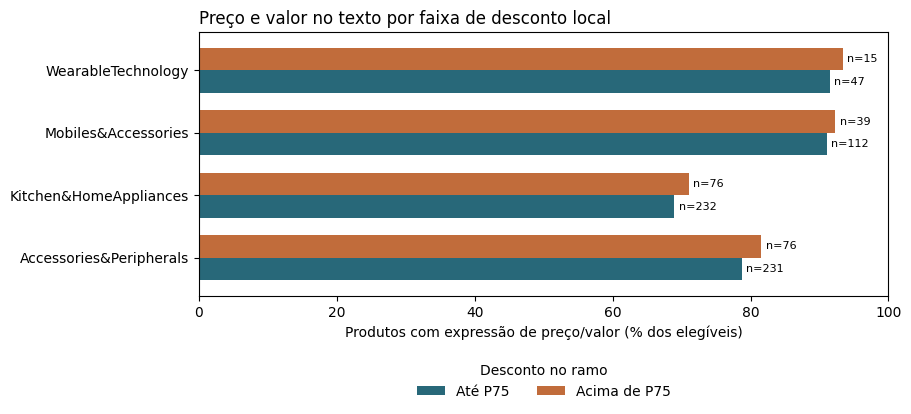

In [40]:
# Cada linha representa um produto elegível. As flags contam presença em qualquer grupo.
visao_ci = visao_textual.merge(flags_aspectos,on="product_id",validate="one_to_one")
faixas_n03 = pd.qcut(visao_ci.actual_price_num,4,labels=["F1","F2","F3","F4"])
visao_ci["Faixa original"] = faixas_n03
visao_ci["Desconto local"] = pd.cut(visao_ci.groupby(["categoria_nivel_1","categoria_nivel_2"])
    .discount_percentage_num.rank(method="average",pct=True),[0,.75,1],
    labels=["Até P75","Acima de P75"],include_lowest=True)
visao_ci["Estabilidade"] = visao_ci.perfil_persistente_n2.map({True:"Persistiu",False:"Mudou"}).where(
    visao_ci.n_n2.ge(30) & ~visao_ci.perfil_completo.isin(["Ausência","Fora do recorte"]))
def presenca_por_recorte(base,comparacao,aspects):
    base=base.loc[base.elegivel_busca]
    out=base.groupby(comparacao,observed=True,dropna=True)[aspects].agg(["sum","size"]).stack(level=0,future_stack=True)
    out.index=out.index.set_names([*comparacao,"Aspecto"])
    out=out.rename(columns={"sum":"Com expressão","size":"Produtos elegíveis"})
    out["%"] = 100*out["Com expressão"]/out["Produtos elegíveis"]
    return out

caminhos = casos.category_original.unique()
subfuncoes = visao_ci.loc[visao_ci.category_original.isin(caminhos)]
contraste_funcional = presenca_por_recorte(subfuncoes.loc[subfuncoes.perfil_completo.isin(["A","B","Alta/baixa"])],
    ["category_original","perfil_completo"],["Compatibilidade","Áudio e chamadas","Preço e valor","Uso e conforto"])
ramos_preco = ["Accessories&Peripherals","Kitchen&HomeAppliances","Mobiles&Accessories","WearableTechnology"]
subramos = visao_ci.loc[visao_ci.categoria_nivel_2.isin(ramos_preco)]
por_preco_ci = presenca_por_recorte(subramos,["categoria_nivel_2","Faixa original"],["Preço e valor","Durabilidade"])
por_desconto_ci = presenca_por_recorte(subramos,["categoria_nivel_2","Desconto local"],["Preço e valor"])
a_ci=visao_ci.loc[visao_ci.perfil_completo.eq("A") & visao_ci.categoria_nivel_2.isin(
    ["Headphones,Earbuds&Accessories","Mobiles&Accessories"])]
por_estabilidade_ci = presenca_por_recorte(a_ci,["categoria_nivel_2","Estabilidade"],["Áudio e chamadas","Preço e valor"])
desc_flags = marcar_aspectos(desc.about_product).set_axis(desc.product_id)
descricoes_comentarios = pd.DataFrame({"Descrição":desc_flags.sum(),"Comentário":flags_aspectos.sum(),
    "Ambos":(desc_flags & flags_aspectos).sum()})
assert len(visao_ci)==1351 and visao_ci.product_id.is_unique
assert (descricoes_comentarios.Ambos.le(descricoes_comentarios.Descrição) &
        descricoes_comentarios.Ambos.le(descricoes_comentarios.Comentário)).all()
display(contraste_funcional.loc[pd.IndexSlice[:,:,"Preço e valor"],:].round(1))
display(por_preco_ci.loc[pd.IndexSlice[["Accessories&Peripherals","Kitchen&HomeAppliances"],:,"Preço e valor"],:].round(1))
display(por_desconto_ci.round(1),por_estabilidade_ci.round(1))
display(descricoes_comentarios.loc[["Compatibilidade","Áudio e chamadas","Instalação e manutenção","Preço e valor"]])
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
v=por_desconto_ci.reset_index().pivot(index="categoria_nivel_2",columns="Desconto local",values="%")
v.plot.barh(ax=ax,color=["#286879","#c16c3b"],width=.72)
ax.set(xlabel="Produtos com expressão de preço/valor (% dos elegíveis)",ylabel="",xlim=(0,100))
ax.set_title("Preço e valor no texto por faixa de desconto local",loc="left")
ax.legend(title="Desconto no ramo",loc="upper center",bbox_to_anchor=(.5,-.21),ncol=2,frameon=False)
for bars,faixa in zip(ax.containers,v.columns):
    denominadores=por_desconto_ci.xs(faixa,level="Desconto local")["Produtos elegíveis"].droplevel("Aspecto")
    ax.bar_label(bars,labels=[f"n={denominadores.loc[k]}" for k in v.index],padding=3,fontsize=8)
plt.show()

### Leitura integrada dos cruzamentos

- **Perfis e função.** Em USBCables, a regra ampliada de preço/valor alcança 16/23 A e 19/22 B. A expressão estrita value for money alcança 6/23 A e 5/22 B. A troca de regra altera inclusive o sentido do contraste. No par do mesmo preço, compatibilidade e acabamento dão contexto que nenhum dos percentuais oferece. Em in-ear há só três produtos B elegíveis, o que limita a comparação local.
- **Preço e desconto.** Em Kitchen&HomeAppliances, preço/valor aparece em 42/52 produtos da F1 e 63/102 da F3. A F4 retorna a 48/67. O padrão não é monotônico. Nos quatro ramos avaliados, o contraste acima e abaixo do P75 local de desconto é inferior a 3 p.p. nesta regra ampla. Esses resultados orientam onde testar regras mais específicas para percepção de valor.
- **Estabilidade e nota.** Áudio/chamadas aparece em 20/20 A sensíveis e 5/5 A persistentes em Headphones. Em Mobiles, 2/5 e 9/22. A presença de expressão pouco separa esses recortes. O fone B e o ferro B trazem críticas a material e entrega, respectivamente, enquanto cabos A e o purificador A trazem elogios locais. O objeto e o contexto ajudam a interpretar o contraste.
- **Descrição e comentário.** Compatibilidade aparece nas duas fontes para 77 produtos, de 438 com a expressão na descrição. Em áudio/chamadas são 213 de 294. Coincidência de assunto orienta seleção de trechos. Confirmação de uma promessa exige verificar a característica e o cenário, como ilustram os cabos e o purificador.

## 7 — Síntese gerencial e encaminhamento ao Power BI

| Pergunta FIAP | Resultado e sustentação | Limite | Aplicação |
|---|---|---|---|
| O que é valorizado? | Há relatos explícitos de encaixe, som, compatibilidade, carga e facilidade. Evidência local nos casos | As expressões de valor e facilidade são frequências literais | Excertos com objeto e caminho, ao lado da cobertura |
| Quais problemas aparecem? | Graves, material, conexão, cabo, dano na entrega e entrada de água surgem nos exemplos. Evidência contextual | A frequência de problemas no catálogo requer anotação e unidade elegível | Fila de investigação por aspecto. Sem indicador de incidência |
| Quais padrões são favoráveis ou desfavoráveis? | Um mesmo bloco pode elogiar áudio e criticar microfone ou material. Valor e graves também aparecem com sinais opostos | Uma nota agregada não atribui polaridade a cada aspecto | Detalhe contextual. Indicadores semânticos condicionados à validação |
| Como os relatos complementam preço, desconto e perfis? | Pares de mesmo preço revelam especificações distintas. Percentuais lexicais variam entre caminho, faixa e estabilidade | Mix, compartilhamento e tamanhos pequenos limitam comparações | Perfis fixos, filtros de caminho e denominador de produtos elegíveis |
| Que ações investigar? | Separar especificação, problema do produto, acessório, logística e serviço | Relatos isolados não estimam impacto financeiro ou incidência | Triagem para documentação, suporte e piloto de anotação |

| Evidência comercial | Evidência textual e hipótese | Próxima verificação |
|---|---|---|
| Cabos USB a INR 349, A/B persistentes | Transferência, conectores e variante de comprimento contextualizam diferenças | Checar SKU, conectores, ensaios de carga e consistência da descrição |
| Fones a INR 499, perfis sensíveis | Encaixe, graves e material separam dimensões ocultas na nota | Revisar especificações e cruzar hipóteses de durabilidade com devoluções |
| Ferros com 43% de desconto | Cabo, peso e estado na entrega pedem leituras distintas | Separar problemas de embalagem, uso e expectativa de preço |
| Celular básico sensível | Autonomia depende de uso. Chamadas, FM e carregador são objetos diferentes | Comparar funções em blocos distintos e coletar condições de uso |
| Purificador A persistente com preço extremo | Entrada, indicador, gosto e instalação descrevem experiências diferentes | Investigar chamados de instalação, pressão e manutenção. Avaliação sanitária exige ensaio próprio |

In [41]:
oraculos_textuais=casos_oraculo(visao_textual)
display(oraculos_textuais.loc[oraculos_textuais.Menção.eq('Bateria')].style.hide(axis='index').format(precision=2,na_rep='Não aplicável'))
# Comparação integral com atributos que o BI já consome; nenhum arquivo é alterado.
bi=pd.read_csv(raiz/'power_bi/dados_modelo/atributos_analiticos_produtos.csv',keep_default_na=False,dtype={'product_id':'string'})
comparar=visao_textual.merge(bi,on='product_id',validate='one_to_one')
mapa={'Bateria':'mencao_bateria','Som e áudio':'mencao_audio','Referência a value for money':'mencao_valor_preco','Referência a facilidade de uso/instalação/limpeza':'mencao_facilidade'}
for atual,legado in mapa.items():assert comparar[atual].astype(bool).equals(comparar[legado].map({True:True,False:False,'True':True,'False':False}).astype('boolean').astype(bool)),legado
legado_perfil=visao_textual.perfil_completo.replace({'Alta/baixa':'Contagem inferior; nota diferente','Baixa/baixa':'Contagem inferior; nota diferente'})
assert legado_perfil.to_numpy().tolist()==visao_textual[['product_id']].merge(bi,on='product_id',validate='one_to_one').perfil_avaliacao_categoria.tolist()
negativos=testes_negativos(tabelas,raiz)
display(negativos)
print('Compatibilidade integral de 1.351 perfis e quatro flags; casos de filtro reconciliados.')

Caso,Menção,Produtos,Denominador elegível,Numerador,Percentual
Base,Bateria,1351,1351,296,21.91
Electronics,Bateria,490,490,203,41.43
Electronics + Home,Bateria,938,938,237,25.27
Electronics / Headphones,Bateria,63,63,27,42.86
A,Bateria,212,212,60,28.30
Alta/baixa,Bateria,241,241,31,12.86
Electronics / A / preço ≤ 899,Bateria,28,28,11,39.29
OfficeProducts,Bateria,31,31,1,3.23
Vazio,Bateria,0,0,0,Não aplicável


,Teste negativo,Detectado
0,Chave duplicada,True
1,FK órfã,True
2,Texto original alterado,True


Compatibilidade integral de 1.351 perfis e quatro flags; casos de filtro reconciliados.


Os seis IDs históricos constam no backup anterior e servem apenas à comparação de versões.

In [42]:
evidencias_casos = pd.concat([evidencias_1,evidencias_2,evidencias_3,evidencias_4,evidencias_5],ignore_index=True)
evidencias_todas = pd.concat([evidencias_casos,auditoria_trechos],ignore_index=True)
originais_por_id = o_canon.set_index("ocorrencia_id")
for linha in evidencias_todas.to_dict("records"):
    r=originais_por_id.loc[linha["Ocorrência"]]
    assert r.product_id==linha["Produto"] and r.grupo_textual_id==linha["Grupo"]
    assert r[linha["Campo"]][linha["Início"]:linha["Fim"]]==linha["Excerto"]
assert set(ids_n03).issubset(evidencias_casos.Produto)
assert evidencias_casos.groupby("Produto").Campo.agg(set).map(lambda s:"about_product" in s and "review_content" in s).all()
assert len(pares_pg)==1370 and len(corpus)==1212 and visao_ci.product_id.is_unique
assert (oraculos_textuais.Numerador<=oraculos_textuais["Denominador elegível"]).all()
assert oraculos_textuais.loc[oraculos_textuais.Caso.eq("Base"),"Numerador"].tolist()==[296,286,524,369]
assert oraculos_textuais.loc[oraculos_textuais.Caso.eq("Vazio"),"Percentual"].isna().all()
assert len(oraculos_textuais)==36 and negativos.Detectado.all()
assert re.search(taxonomia["Autonomia e carga"][0],"charging money")
assert "Outro assunto" in auditoria_trechos.Leitura.values
assert "Insuficiente" in evidencias_casos.Leitura.values
print(f"{len(evidencias_todas)} trechos conferidos por offset no original; {len(ids_n03)} casos do N03 e 1 comparador.")
print("36 combinações de filtro e família lexical; 4 flags históricas em 1.351 IDs.")

# Confere a proporção independentemente da agregação por grupo.
usb_a = visao_ci.loc[visao_ci.category_original.str.endswith("|USBCables") & visao_ci.perfil_completo.eq("A")]
assert len(usb_a)==23 and usb_a["Preço e valor"].sum()==16
assert all(casos.loc[pid,"grupos_textuais"]==1 for pid in ids_n03)

57 trechos conferidos por offset no original; 8 casos do N03 e 1 comparador.
36 combinações de filtro e família lexical; 4 flags históricas em 1.351 IDs.


O BI pode apresentar cobertura, grupos e presença literal com denominação explícita, acompanhados de proveniência e contexto comercial. A nota e o perfil devem continuar no grão de produto. Comparar os oráculos em pandas é uma etapa anterior à homologação no Power BI Desktop.

O Notebook 05 pode usar as regras como baseline de recuperação de candidatos, com unidades de anotação por trecho, objeto e aspecto. O NMF vigente organiza temas e vocabulário para leitura exploratória. Classificar polaridade, medir erro e liberar indicadores de problemas requer anotação humana independente e um teste separado por componentes de dependência.

O primeiro uso dos resultados é melhorar a triagem por função. Em cabos, fones e ferros, atributos e condições de uso acrescentam explicações que os indicadores do catálogo não oferecem. No celular e no purificador, as hipóteses apontam a necessidade de documentação técnica, suporte e relatos contextualizados.